In [1]:
import os
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy
from IPython.display import display, Markdown
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="This pattern is interpreted as a regular expression")
pd.set_option("display.max_colwidth", 120, "display.width", 220, "display.max_columns", 60)

In [2]:
# ---- Paths (relative to analysis/tenant-headlines/) ----
DATA_DIR = Path("../../data/headlines")
PREPARED_PATH = DATA_DIR / "prepared" / "headlines_prepared.csv"
ANNOTATIONS_PATH = DATA_DIR / "annotations" / "framing_annotations.csv"
REVIEW_PATH = DATA_DIR / "review" / "human_review.csv"                       # created here; the human fills it in
REVIEW_LABELS_PATH = Path(os.environ.get("HEADLINE_REVIEW_FILE", REVIEW_PATH))  # where completed labels are read from

# ---- Reproducibility ----
SEED = 42
SPACY_MODEL = "en_core_web_sm"

# ---- Human-review sample design ----
PILOT_N = 20                    # used to refine definitions; never used to score the measures
VALIDATION_RANDOM_N = 80        # stratified random validation headlines
VALIDATION_TARGETED_N = 20      # deliberately difficult validation headlines
RANDOM_ALLOCATION = {"tenant": 28, "landlord": 26, "both": 26}   # per mention type; half predicted-positive, half predicted-negative
PILOT_ALLOCATION = {"tenant": 8, "landlord": 6, "both": 6}
MAX_PER_OUTLET_SHARE = 0.12     # soft cap on any one outlet within the random component
MAX_PER_YEAR_SHARE = 0.15       # soft cap on any one year within the random component
REGENERATE_REVIEW = False       # True overwrites an existing review file even if it already contains labels (not recommended)

# ---- Interpretation thresholds ----
MIN_POSITIVES = 10              # fewer human-positive (or predicted-positive) headlines than this = estimate flagged as unreliable
LOW_PRECISION, LOW_RECALL = 0.70, 0.60   # a central measure below these (with enough data) triggers a request for more review

# ---- Exploratory vocabulary comparison ----
LEXICAL_MIN_DOCS = 8            # n-grams must appear in at least this many headlines
LEXICAL_PRIOR = 500             # strength of the informative Dirichlet prior
TOP_TERMS = 15
N_CLUSTERS = 6

# ---- Display ----
COLORS = {"tenant": "#2a78d6", "landlord": "#eb6834", "both": "#6b6a66"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.titleweight": "bold", "axes.titlesize": 11, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True, "legend.frameon": False,
})

# 02 · Measure and validate

**Goal.** Turn each headline into transparent, comparable observations of *how tenants and landlords are portrayed*, then set up (and, once labels exist, run) a human check of those measurements.

**Unit of analysis.** One observation = one *headline × group* pair. A headline mentioning both groups gives two observations, one for each group. Repeated mentions of the same group in one headline are combined (a dimension is "present" if any mention triggers it), so repetition cannot inflate counts.

**The scheme is symmetric by construction.** The same lexicons and the same grammatical rules are applied to tenants and to landlords. Nothing below is a "tenant dictionary" or a "landlord dictionary"; the only group-specific lists are a pair of epithet lists, and their sizes are printed so the balance can be checked.

| Block | Dimensions (each yes/no, several can be true at once) | How it is observed in the headline |
|---|---|---|
| **Agency** | `act_initiate`, `act_resist`, `harm_experienced`, `assist_received` | The group is the *doer* of an action on others or the world (evict, raise, sell, build) · the group *responds, resists or asserts rights* (fight, sue, protest, appeal, win) · the group *undergoes* harm or hardship (evicted, face eviction, squeezed, killed) · the group is the *recipient* of help (protected, supported, given relief) |
| **Voice** | `voice_speaks`, `voice_demands`, `voice_via_org`, `discussed_by_others` | The group speaks or is quoted (says, tells, ‘…’ attributed to them) · makes demands or claims (demand, urge, ask, want, blame) · is spoken for by an advocacy body · *or* is discussed by someone else (a study, official or court acts or speaks about them) |
| **Constituency** | `const_org`, `const_collective`, `const_policy` | Organisations, associations, unions, advocates tied to the group · collective-interest language ("tenants' rights", "landlord concerns") · policy-representation language (consultation, representation, "tenant-friendly") |
| **Individualization** | `ind_level` ∈ individual / group / institutional | Singular personal case (a tenant, a 72-year-old landlord) vs a plural or generic group vs corporate/organised actors |
| **Harm, blame, stigma** | `harm_event`/`harm_state`, `wrongdoing`, `responsibility`, `derogatory` | Hardship ≠ alleged wrongdoing (charged, fined, sued, fraud) ≠ attributed responsibility (blamed, "to blame") ≠ explicitly derogatory words (deadbeat, slumlord, "from hell") |
| **Topics** (headline level) | eviction · affordability · conditions · dispute · regulation · organizing · investment · crime | Keyword families that never include the group words themselves |

**Recognition or legitimacy is not scored.** There is no composite "legitimacy" number. What can actually be seen in a headline is *voice* (does the group speak or demand?), *representation* (are organisations or advocates attached to it?) and *attribution* (who is named as actor, who as target?). Those are reported as separate, countable signals.

**Grammar is kept separate from meaning.** `gram_role` records the grammatical position (active subject, passive subject, object ...) while the dimensions above record the *semantic* role. "Tenants face eviction" is grammatically active but semantically harm-experiencing; "tenants protected from eviction" is grammatically passive but semantically assistance-receiving, not a loss of agency.

**Context rules.** A cue is dropped when it is negated ("landlords *can't* evict", "*not* to blame", charges *dropped*) and logged as `ctx_negated`. Cues inside quotation marks are flagged (`ctx_quoted`); a derogatory word that appears only inside quotes is counted as `derogatory_quoted`, not `derogatory`. Allegation language (alleged, accused, charged ...) is flagged as `ctx_alleged` next to any wrongdoing or derogatory cue.

All of this is a rule-based *diagnostic*: it reuses the idea of the earlier lexicons and spaCy dependency parsing but attributes each cue to the right group instead of scoring whole headlines. Rules make mistakes, which is why the second half of this notebook builds a human-review file.

## 1. Load the prepared data

In [3]:
prepared = pd.read_csv(PREPARED_PATH)
frame = prepared[prepared["mention_group"].isin(["tenant", "landlord", "both"])].reset_index(drop=True)
print(f"{len(prepared):,} prepared rows → {len(frame):,} rows mention tenants and/or landlords "
      f"(headlines naming only an institution such as the Landlord and Tenant Board, or only the legal concept of tenancy, are not analysed as group portrayals)")
display(frame.groupby("mention_group").agg(rows=("id", "size"), distinct_story_families=("family_id_near", "nunique")))

7,726 prepared rows → 7,587 rows mention tenants and/or landlords (headlines naming only an institution such as the Landlord and Tenant Board, or only the legal concept of tenancy, are not analysed as group portrayals)


,rows,distinct_story_families
mention_group,,
both,1073,821
landlord,2038,1528
tenant,4476,3590


## 2. Lexicons

Each lexicon entry says what it means *for the group that fills a given grammatical role*. Verbs have one reading when the group is the subject (agent) and another when it is the object or passive subject (patient): "evict" makes the subject an initiator and the object a harmed party; "help" makes the object an assistance recipient; "blame" makes the object responsible and the subject a claim-maker.

In [4]:
TENANT_TOKS = {"tenant", "tenants", "renter", "renters"}
LANDLORD_TOKS = {"landlord", "landlords"}
GROUP_TOKS = {"tenant": TENANT_TOKS, "landlord": LANDLORD_TOKS}
OTHER = {"tenant": "landlord", "landlord": "tenant"}

TENANT_RE = re.compile(r"\b(?:tenants?|renters?)\b", re.I)
LANDLORD_RE = re.compile(r"\blandlords?\b", re.I)
INSTITUTION_RE = re.compile(
    r"\b(?:landlords?\s*(?:and|&|/|-|–)?\s*tenants?\s+(?:board|act|tribunal|branch|relations(?:\s+act)?|advisory\s+board)"
    r"|residential\s+tenanc(?:y|ies)\s+(?:act|board|branch|commission|tribunal|office|regulation|dispute\s+resolution)"
    r"|tenant\s+protection\s+act"
    r"|protecting\s+tenants\s+and\s+strengthening\s+community\s+housing\s+act"
    r"|rental\s+housing\s+(?:tribunal|enforcement\s+unit))\b", re.I)

# ---------------------------------------------------------------------------------------------
# VERB LEXICON: lemma -> (dims when the group is the SUBJECT/agent, dims when it is the OBJECT/patient)
# The same table is applied to both groups; nothing here is specific to tenants or landlords.
# ---------------------------------------------------------------------------------------------
def _v(subj=(), obj=()):
    return (tuple(subj), tuple(obj))

VERB_LEX = {}
def add_verbs(words, subj=(), obj=()):
    for w in words.split():
        VERB_LEX[w] = _v(subj, obj)

# initiating action on others / the world
add_verbs("evict displace oust renovict demovict", subj=["initiate"], obj=["harm"])
add_verbs("raise hike increase boost jack impose serve terminate cancel end cut sell list advertise purchase buy convert demolish "
          "renovate build develop invest launch open hire sign start create propose plan decide order ban limit cap enforce collect inspect "
          "offer lease rent seek expand acquire lower reduce freeze waive extend", subj=["initiate"])
# resisting, responding, asserting rights (legal / collective action) - same for both groups
add_verbs("fight challenge appeal resist protest rally march strike organize organise mobilize mobilise petition win defend refuse reject "
          "oppose withhold unionize unionise campaign counter retaliate", subj=["resist"])
add_verbs("sue", subj=["resist"], obj=["wrongdoing"])
add_verbs("file", subj=["resist"])
# speech: speaking, making demands/claims
add_verbs("say tell claim argue warn explain insist note add describe recall reveal admit lament complain react respond speak voice share "
          "decry criticize criticise slam denounce vow pledge reflect", subj=["speaks"])
add_verbs("ask urge demand plead press request lobby beg implore", subj=["speaks", "demands"])
add_verbs("want", subj=["demands"])
add_verbs("confirm announce state comment release testify", subj=["speaks"])
add_verbs("blame", subj=["speaks", "demands"], obj=["responsibility"])
add_verbs("accuse", subj=["speaks", "demands"], obj=["wrongdoing"])
# experiencing harm (group as experiencer subject)
add_verbs("face fear struggle suffer lose risk endure scramble cope flee escape die", subj=["harm"])
# harm done to the group (group as object/passive subject); crimes/misconduct committed by the group (subject)
add_verbs("hurt harm injure kill stab shoot rob scam defraud cheat harass abuse threaten terrorize terrorise exploit gouge overcharge "
          "neglect discriminate assault attack punish target hit squeeze strand trap burden shortchange mislead steal", subj=["wrongdoing"], obj=["harm"])
add_verbs("trash damage squat vandalize vandalise break flout violate breach ignore", subj=["wrongdoing"])
# alleged wrongdoing / sanction (group as object/passive subject)
add_verbs("charge", subj=["initiate"], obj=["wrongdoing"])
add_verbs("fine convict arrest sentence penalize penalise sanction cite ticket probe investigate indict jail bust prosecute", obj=["wrongdoing"])
# receiving assistance
add_verbs("help protect support aid assist shield rescue house shelter compensate reimburse subsidize subsidise relieve save back champion "
          "welcome accommodate rehouse", obj=["assist"])
add_verbs("benefit", subj=["assist"])
add_verbs("give provide grant", obj=["assist"])      # indirect object only (handled by role logic)

# phrasal verbs decided by particle/prep child
PHRASAL = {
    ("push", "out"): _v(["initiate"], ["harm"]), ("push", "off"): _v(["initiate"], ["harm"]), ("push", "up"): _v(["initiate"]),
    ("push", "for"): _v(["speaks", "demands"]), ("push", "back"): _v(["resist"]), ("push", "to"): _v(["speaks", "demands"]),
    ("kick", "out"): _v(["initiate"], ["harm"]), ("lock", "out"): _v(["initiate"], ["harm"]), ("force", "out"): _v(["initiate"], ["harm"]),
    ("drive", "out"): _v(["initiate"], ["harm"]), ("price", "out"): _v(["initiate"], ["harm"]), ("throw", "out"): _v(["initiate"], ["harm"]),
    ("turf", "out"): _v(["initiate"], ["harm"]), ("boot", "out"): _v(["initiate"], ["harm"]), ("shut", "out"): _v(["initiate"], ["harm"]),
    ("speak", "out"): _v(["speaks"]), ("stand", "up"): _v(["resist"]), ("fight", "back"): _v(["resist"]), ("call", "for"): _v(["speaks", "demands"]),
    ("call", "out"): _v(["speaks", "demands"], ["wrongdoing"]), ("call", "on"): _v(["speaks", "demands"]), ("hit", "with"): _v([], ["harm"]),
    ("slap", "with"): _v([], ["wrongdoing"]), ("hold", "accountable"): _v(["speaks", "demands"], ["responsibility"]),
}
VERB_LEX.update({"kick": _v(["initiate"], ["harm"]), "lock": _v(["initiate"], ["harm"]), "force": _v(["initiate"], ["harm"]),
                 "drive": _v([], []), "price": _v([], []), "push": _v(["initiate"]), "take": _v(), "pay": _v(), "get": _v(), "receive": _v(), "qualify": _v(),
                 "speak": _v(["speaks"]), "call": _v(), "stand": _v(), "hold": _v(), "slap": _v([], ["wrongdoing"])})
ASSIST_NOUNS = {"relief", "rebate", "subsidy", "subsidies", "supplement", "grant", "grants", "benefit", "benefits", "funding", "compensation", "credit",
                "refund", "assistance", "aid", "help", "support", "payout", "cheque", "bonus", "break", "incentive", "incentives", "protection",
                "protections", "financing", "loan", "loans"}
RECEIVE_VERBS = {"get", "receive", "qualify", "eligible", "gain", "win"}

# noun cues: noun lemma -> dims when the group modifies it / is its object ("tenant X", "X for tenants")
NOUN_HARM = {"hardship", "hardships", "struggle", "struggles", "woe", "woes", "plight", "crisis", "displacement", "eviction", "evictions", "homelessness",
             "poverty", "anxiety", "fear", "fears", "stress", "burden", "squeeze", "harassment", "discrimination", "intimidation", "exploitation",
             "mistreatment", "abuse", "misery", "desperation", "despair", "limbo", "trouble", "loss", "losses", "pain", "suffering", "nightmare",
             "shortage", "victim", "victims", "casualty", "casualties", "turmoil", "uncertainty", "distress", "peril", "danger", "risk", "risks", "scam", "scams", "fraud"}
NOUN_WRONG = {"charge", "charges", "allegation", "allegations", "lawsuit", "lawsuits", "complaint", "complaints", "violation", "violations", "offence",
              "offences", "offense", "conviction", "probe", "investigation", "fine", "fines", "penalty", "penalties", "misconduct", "wrongdoing", "crime",
              "crimes", "assault", "theft", "illegality", "scheme"}
NOUN_ASSIST = ASSIST_NOUNS
VICTIM_PREPS = {"against", "on", "of", "for", "among", "facing", "toward", "towards", "targeting", "hitting"}
PERP_PREPS = {"by", "of", "for", "against", "over"}

# adjectives / participles that, when modifying (or predicated of) the group, describe hardship
HARDSHIP_ADJ = {"struggling", "desperate", "vulnerable", "displaced", "evicted", "homeless", "stranded", "squeezed", "strapped", "suffering", "scared",
                "afraid", "fearful", "anxious", "stressed", "trapped", "forced", "priced-out", "unhoused", "stuck", "worried", "frustrated", "angry",
                "burdened", "victimized", "victimised", "overburdened", "cash-strapped", "exhausted", "shut-out", "left-behind", "hard-hit", "hit",
                "harassed", "abused", "mistreated", "threatened", "locked-out", "kicked-out", "tormented", "terrorized", "terrorised", "isolated",
                "unprotected", "unsafe", "powerless", "helpless", "overcharged", "gouged", "scammed", "defrauded", "ripped-off", "robbed", "attacked",
                "injured", "killed", "dead", "dying", "hungry", "cold", "sick", "ill", "broke", "bankrupt", "ruined", "devastated", "stung"}
WRONG_ADJ = {"illegal", "unlawful", "negligent", "neglectful", "fraudulent", "abusive", "violent", "criminal", "guilty", "liable", "unlicensed",
             "discriminatory", "corrupt", "lawbreaking", "delinquent", "dishonest", "deceptive", "reckless"}

# explicit derogatory language - one shared list for both groups, plus group-specific epithets of similar size
DEROG_SHARED_ADJ = {"bad", "worst", "nightmare", "nightmarish", "problem", "problematic", "rogue", "shady", "sleazy", "sleazeball", "greedy", "ruthless", "notorious", "infamous",
                    "heartless", "predatory", "deadbeat", "freeloading", "parasitic", "scummy", "crooked", "thuggish", "evil", "dirty", "toxic",
                    "lazy", "entitled", "irresponsible", "unscrupulous", "slimy", "cruel", "callous", "miserly", "slum", "selfish", "vile", "horrible",
                    "terrible", "awful", "difficult", "troublesome", "unruly", "nasty", "shameless", "hateful", "monstrous", "shocking", "bullying"}
DEROG_SHARED_NOUN = {"scum", "scumbag", "crook", "thug", "bully", "parasite", "leech", "cheat", "swindler", "con", "liar", "criminal", "monster", "pig", "creep", "freeloader", "deadbeat", "scammer", "fraudster", "predator"}
DEROG_GROUP_NOUN = {"tenant": {"squatter", "squatters", "squat", "freeloader", "freeloaders", "deadbeat", "deadbeats", "welfare", "junkie", "junkies", "druggie", "vermin", "pest", "pests"},
                    "landlord": {"slumlord", "slumlords", "gouger", "gougers", "profiteer", "profiteers", "exploiter", "exploiters", "tyrant", "tyrants", "overlord", "overlords", "vampire", "vampires", "greedy-landlord", "miser", "vulture", "vultures"}}
DEROG_PHRASES = [r"from hell", r"professional tenant", r"professional renter", r"rent[- ]gouging", r"gouging", r"slum\s*lord", r"tenant\s+from\s+hell",
                 r"landlord\s+from\s+hell", r"horror\s+(?:landlord|tenant)", r"scam\s+(?:landlord|tenant)", r"worst\s+(?:landlord|tenant)s?",
                 r"bad\s+(?:landlord|tenant|renter)s?", r"problem\s+(?:landlord|tenant|renter)s?"]

# constituency
ORG_NOUNS = {"association", "associations", "union", "unions", "group", "groups", "coalition", "coalitions", "organization", "organisation", "organizations",
             "organisations", "federation", "council", "alliance", "network", "society", "committee", "lobby", "lobbyist", "lobbyists", "advocate", "advocates",
             "advocacy", "activist", "activists", "organizer", "organizers", "organiser", "organisers", "spokesperson", "spokesman", "spokeswoman", "representative",
             "representatives", "rep", "reps", "caucus", "movement", "collective", "league", "chapter", "campaigners"}
ADVOCACY_NOUNS = {"advocate", "advocates", "activist", "activists", "organizer", "organizers", "organiser", "organisers", "union", "unions", "association", "associations",
                  "coalition", "federation", "alliance", "lobby", "lobbyist", "lobbyists", "spokesperson", "spokesman", "spokeswoman"}
ORG_NAMES = re.compile(r"\b(?:acorn|frpo|cfaa|fmta|ocap|tenant\s+resource|tenants?\s+rights\s+(?:action|coalition)|tenant\s+union|tenants?'\s*union|"
                       r"landlord\s+bc|bc\s+landlord\s+association|landlord\s+association|apartment\s+association|rental\s+housing\s+(?:association|providers)|"
                       r"small\s+landlords?\s+(?:group|association)|real\s+estate\s+board|reit)\b", re.I)
COLLECTIVE_HEADS = {"rights", "right", "interests", "interest", "concerns", "concern", "voice", "voices", "demands", "demand", "priorities", "needs", "wishes",
                    "complaints", "issues", "agenda", "wishlist", "position", "positions", "perspective", "perspectives",
                    "views", "view", "side", "interests", "community", "industry", "sector", "class", "bloc", "base", "solidarity", "unity"}
POLICY_ACTORS = re.compile(r"\b(?:government|province|provincial|federal|ottawa|queen's park|city\s+(?:council|hall)|council|councillors?|mayor|minister|premier|"
                           r"mpp|mp|mla|mlas|mpps|ndp|liberals?|conservatives?|greens?|party|legislature|lawmakers?|politicians?|senator|feds|trudeau|ford|eby|"
                           r"carney|poilievre|horgan|notley|kenney|smith|houston|pallister|couillard|legault|wynne|mckenna|moe|bill\s+\d+|committee)\b", re.I)
POLICY_REP = re.compile(r"\b(?:consult\w*|meet(?:s|ing|ings)?\s+with|round\s*table|stakeholders?|lobby\w*|represent\w*|spokes\w*|advisory|task\s*force|"
                        r"bill\s+of\s+rights|on\s+behalf\s+of|sides?\s+with|sided\s+with|siding\s+with|listen\w*\s+to|hear\w*\s+from|have\s+a\s+say|seat\s+at\s+the\s+table|"
                        r"friendly|favou?rs?|favou?ring|champion\w*|backs?|backing|defends?)\b", re.I)

# individualization
INSTITUTIONAL_MODS = {"corporate", "company", "companies", "firm", "firms", "developer", "developers", "reit", "reits", "institutional", "big", "large", "largest",
                      "major", "multinational", "foreign", "offshore", "property-management", "management", "government", "city", "municipal", "provincial", "federal",
                      "public", "non-profit", "nonprofit", "housing-authority", "investor", "investors", "financialized", "private-equity", "billion-dollar",
                      "billionaire", "billionaires", "wall-street", "big-box", "chain", "owner-operator", "mega", "conglomerate", "corporation", "corporations", "inc", "ltd",
                      "association", "group", "industry", "sector", "union", "federation", "coalition", "organization"}
PERSONAL_DESC = re.compile(r"\b(?:\d{1,3}[- ]year[- ]old|single\s+(?:mother|mom|father|dad|parent)|mother|mom|father|dad|grandmother|grandfather|grandma|grandpa|"
                           r"senior|elderly|widow|couple|family|student|veteran|woman|man|girl|boy|teen|teenager|resident|neighbou?r|pensioner|immigrant|newcomer|"
                           r"refugee|nurse|teacher|doctor|worker|employee|mr\.?|mrs\.?|ms\.?|dr\.?)\b", re.I)

# context
NEG_TOKENS = {"no", "not", "never", "without", "cannot", "n't", "nor", "neither", "none", "nobody", "deny", "denies", "denied", "denying", "refute", "refutes",
              "dismiss", "dismisses", "dismissed", "drop", "drops", "dropped", "stay", "stayed", "clear", "cleared", "clears", "acquit", "acquitted", "acquits",
              "exonerate", "exonerated", "lack", "lacks", "lacking", "missing", "false", "baseless", "unfounded", "untrue", "myth", "wrongly", "falsely", "bogus", "unproven", "debunk", "debunked"}
HEDGES = re.compile(r"\b(?:alleged(?:ly)?|accused|accuses|accusing|allegations?|suspect(?:ed)?|reportedly|claims?|claimed|claiming|police\s+say|"
                    r"according\s+to|says?|said|may\s+have|possibly|apparently|purportedly|rumou?red|accusations?|charged|charges?)\b", re.I)
QUOTE_RE = re.compile(r"[\"“](.+?)[\"”]|‘(.+?)’|(?<![\w])'(.+?)'(?![\w])")
SPEECH_FRAME = {"say", "tell", "claim", "argue", "warn", "find", "show", "suggest", "report", "reveal", "predict", "estimate", "note", "believe", "think",
                "expect", "announce", "confirm", "admit", "advise", "recommend", "survey", "poll", "study", "conclude", "determine", "rule", "decide", "explain",
                "caution", "urge-others", "propose", "promise", "vow", "pledge"}
OTHER_SPEAKER_RE = re.compile(r"\b(?:police|opp|rcmp|officials?|experts?|economist|analysts?|study|survey|poll|report|researchers?|mayor|minister|premier|"
                              r"government|province|city|council|councillor|mpp|mp|mla|court|judge|board|tribunal|cmhc|rbc|td|bmo|cibc|scotiabank|advocates?|"
                              r"lawyer|critics?|opposition|ndp|liberals?|conservatives?|spokes\w+|says?|said|according\s+to|finds?|shows?)\b", re.I)

# topics (headline-level, multi-label). Group words are NOT part of any topic pattern.
TOPICS = {
    "eviction": r"\bevict\w*|renovict\w*|demovict\w*|\bn1[23]\b|\bn4\b|notice\s+to\s+(?:vacate|end)|kick(?:ed|s|ing)?\s+out|lock(?:ed|s|ing)?\s*out|forced\s+out|turfed|bailiff|sheriff|displac\w*|homeless\w*|nowhere\s+to\s+(?:go|live)|unhoused|vacate",
    "affordability": r"afford\w*|rent\s+(?:increase|hike|rise|spike|surge|burden|relief|prices?|bank|supplement|subsid\w*|cost|growth|gap)s?|rents?\s+(?:rise|rises|soar\w*|jump\w*|climb\w*|skyrocket\w*|surge\w*|spike\w*|hit|top)|\bhigh(?:er)?\s+rents?|cost\s+of\s+living|priced\s+out|housing\s+costs?|average\s+rent|median\s+rent|rent\s+report|bidding\s+war|\binflation|cost\s+of\s+(?:rent|housing)|paying\s+more|rent\s+too\s+high|income|poverty|low[- ]income|food\s+bank|gouging|price\s+gouging|above[- ]guideline",
    "conditions": r"mou?ld|repairs?|pests?|bed\s?bugs?|cockroach\w*|infest\w*|\bheat(?:ing)?\b|no\s+heat|air\s+condition\w*|\ba/?c\b|unsafe|uninhabitable|disrepair|maintenance|elevator|leak\w*|flood\w*|asbestos|sewage|fire\s+(?:safety|code)|inspection|bylaw\s+(?:officer|enforcement)|conditions|living\s+conditions|broken|water\s+damage|infestation|hazard\w*|slum\w*|squalor|rodents?|mice|rats?|hot\s+water|without\s+(?:heat|water|power|electricity)|boil\s+water|evacuat\w*|fire\b|blaze|smoke|power\s+outage|noise|mold",
    "dispute": r"disput\w*|\bltb\b|\brtb\b|tribunal|\bcourt\b|\bjudge\b|ruling|lawsuit|\bsue[ds]?\b|suing|ordered\s+to|hearing|mediation|arrears|unpaid|owed|\bowes?\b|damages|deposit|small\s+claims|arbitrat\w*|\bclaims?\b|\bappeal\w*|\bfeud\b|\bbattle\b|\bclash\w*|\bfight\w*|\bfighting\b|verdict|convict\w*|\bcharged\b|\bcharges\b|\bsentenced\b|allegation\w*|accus\w*|lawyer|legal\b|human\s+rights\s+(?:tribunal|complaint)|\bswindl\w*|\bscam\w*|fraud\w*|\blawsuits?\b|\bsettle\w*|breach\w*|lien|seiz\w*|bailiff|property\s+damage|non-?payment|nonpayment|refus\w+\s+to\s+pay",
    "regulation": r"rent\s+(?:control|cap|freeze|guideline|regulation|registry)|legislat\w*|\bbill\s+\d+|\bbill\b|\blaws?\b|\bact\b|regulat\w*|\bbylaw\w*|licens\w*|registry|policy|policies|guideline\w*|\bminister\b|reform\w*|moratorium|\brules?\b|amend\w*|protections?\b|new\s+rules|provincial\s+government|\bban(?:s|ned|ning)?\b|crack\w*\s+down|\bcap\b|\bfreeze\b|\bgovernment\b|\bcity\s+council\b|council\s+(?:votes|approves|passes)|legal\s+changes|enforcement|vacancy\s+control",
    "organizing": r"\bunions?\b|rent\s+strike|protest\w*|\brall(?:y|ies|ied)\b|organiz\w*|organis\w*|advoca\w*|activis\w*|campaign\w*|petition\w*|coalition|acorn|mobiliz\w*|\bmarch(?:es|ed)?\b|demonstrat\w*|solidarity|collective|association|lobby\w*|town\s+hall|\bvigil\b|speak(?:s|ing)?\s+out|grassroots|\bstrike\b",
    "investment": r"invest\w*|\breits?\b|mortgage\w*|interest\s+rates?|\bprofits?\b|profitab\w*|financiali[sz]\w*|private\s+equity|real\s+estate|\bcondos?\b.{0,20}\binvest|rental\s+income|cash\s+flow|\bcapital\s+gains?\b|short[- ]term\s+rentals?|airbnb|\bsell(?:s|ing)?\b|\bbuy(?:s|ing)?\b|purchase\w*|acquir\w*|portfolio|\bflip\w*|speculat\w*|\bdevelop(?:er|ers|ment)\b|property\s+(?:tax|taxes|manage\w*|values?)|housing\s+market|\bmarket\b|business|\bbillion\b|\bmillion\b|\bbuyers?\b|\bsellers?\b|vacancy\s+rate|\byields?\b|\bequity\b|\bunits?\b.{0,20}\bsold",
    "crime": r"\bkill\w*|\bshot\b|\bshoot\w*|\bstab\w*|murder\w*|\bassault\w*|\bpolice\b|\bopp\b|\brcmp\b|arrest\w*|charged\s+with|\bcrime\w*|\bhomicide\b|\bdead\b|\bdeath\b|\bdies\b|\barson\b|\brob\w*|\btheft\b|\bthief\b|\bburglar\w*|\bhostage\b|\bstandoff\b|\bthreat\w*|\bshooting\b|\bmanslaughter\b|\bgun\b|\bweapon\w*|sentenced|convicted|\bprison\b|\bjail\b|sexual|\bdrug\w*|\bfentanyl\b|\bgrow[- ]op\b|\bpot\b|cannabis|fire\s+(?:kills|claims)|\bfound\s+dead\b|\binjur\w*",
}
TOPIC_RES = {k: re.compile(v, re.I) for k, v in TOPICS.items()}

lex_sizes = pd.DataFrame({
    "entries": {
        "verbs (both groups)": len(VERB_LEX), "hardship adjectives": len(HARDSHIP_ADJ), "harm nouns": len(NOUN_HARM), "wrongdoing nouns": len(NOUN_WRONG),
        "assistance nouns": len(NOUN_ASSIST), "organisation nouns": len(ORG_NOUNS), "shared derogatory words": len(DEROG_SHARED_ADJ | DEROG_SHARED_NOUN),
        "tenant-specific epithets": len(DEROG_GROUP_NOUN["tenant"] - {"squatter", "squatters", "squat", "welfare", "pest", "pests"}) + 2,
        "landlord-specific epithets": len(DEROG_GROUP_NOUN["landlord"]) + 1}})
print("Lexicon sizes (the group-specific epithet lists are deliberately balanced):")
display(lex_sizes.T)

Lexicon sizes (the group-specific epithet lists are deliberately balanced):


,verbs (both groups),hardship adjectives,harm nouns,wrongdoing nouns,assistance nouns,organisation nouns,shared derogatory words,tenant-specific epithets,landlord-specific epithets
entries,235,67,50,28,28,43,67,10,19


## 3. The measurement engine

For every group mention the engine looks at: the verb that governs it and the role it plays (subject, object, passive subject, agent of a *by*-phrase), adjectives and participles that describe it, nouns it modifies or is the object of ("tenant crisis", "relief for landlords"), organisation words it is attached to, and quotation attribution. When the parser gives no relation for a short headline fragment, a tight left/right adjacency rule is used. Cues in a different clause from the mention are ignored, and a cue is attributed only to the group it actually concerns (in "landlord evicts tenant" the landlord gets *initiate* and the tenant gets *harm*).

In [5]:
DIMS = ["act_initiate", "act_resist", "harm_event", "harm_state", "assist_received", "voice_speaks", "voice_demands", "voice_via_org",
        "discussed_by_others", "const_org", "const_collective", "const_policy", "wrongdoing", "responsibility", "derogatory", "derogatory_quoted"]
DIM_MAP = {"initiate": "act_initiate", "resist": "act_resist", "harm": "harm_event", "assist": "assist_received", "speaks": "voice_speaks",
           "demands": "voice_demands", "wrongdoing": "wrongdoing", "responsibility": "responsibility"}
VERB_LEX.update({"offer": _v(["initiate"], ["assist"]), "order": _v(["initiate"], ["wrongdoing"]), "ignore": _v(["wrongdoing"], ["harm"]), "relocate": _v(["initiate"]),
                 "lose": _v(["harm"])})
add_verbs("fuel cause trigger worsen exacerbate inflate spur stoke", subj=["responsibility"])
add_verbs("murder beat stalk molest rape torch", subj=["wrongdoing"], obj=["harm"])
PASSIVE_PRONE = {k for k, (sd, od) in VERB_LEX.items() if od}
LEGAL_OBJ = {"appeal", "bid", "case", "fight", "battle", "challenge", "lawsuit", "hearing", "ruling", "court", "vote", "election", "dispute", "claim", "suit"}
WRONG_OBJ = NOUN_WRONG | {"fine", "charge", "lawsuit", "jail", "prison", "trial", "court", "sentence", "penalty", "sanction"}
VICTIM_NOUNS = {"assault", "theft", "fraud", "scam", "scams", "crime", "crimes"}
RESP_NOUNS = {"blame", "fault", "responsibility", "accountability"}
RESP_ADJ = {"responsible", "accountable", "culpable", "liable"}
CHAIN_BREAK = {":", ";", "—", "–", "|"}

COPULAR_LINK = {"be", "feel", "remain", "stay", "seem", "look", "become", "get", "grow", "leave", "sit", "live", "find", "report", "say"}
PHRASE_HARM = re.compile(
    r"at risk\b|can.?t afford|cannot afford|can.?t pay|nowhere to (?:go|live|turn)|priced out|forced (?:out|to (?:leave|move|sell|choose|pay|live|vacate))|"
    r"(?:lose|losing|lost|loses) (?:their|his|her|its|a) (?:home|apartment|housing|unit|income|money|savings|rent)|left (?:homeless|without|with)|"
    r"at risk of|in (?:crisis|distress|limbo|trouble|danger|fear|poverty)|out of pocket|stuck with|living in (?:fear|poverty|squalor|mou?ld|cars?|tents?)|"
    r"(?:hit|squeezed|crushed|slammed) (?:by|with|hard)|hit hard|going without|without (?:heat|water|power|electricity|hot water|a home)|"
    r"rent burden\w*|housing insecurity|\bout \$[\d,.]+\s?[km]?\b", re.I)
PHRASE_RESP = re.compile(r"\bto blame\b|\bat fault\b|\bresponsible for\b|\bbehind the (?:crisis|surge|spike|shortage|problem|rise)\b", re.I)
BLAME_OBJ = re.compile(r"\bblam(?:e|es|ing)\s+(?:the\s+|on\s+)?(?:[\w'’-]+\s+){0,1}?(landlords?|tenants?|renters?)", re.I)
RESP_GAP = {"be", "is", "are", "was", "were", "to", "partly", "largely", "mostly", "also", "not", "solely", "entirely", "equally", "wholly", "'re", "being", "may", "might", "could", "also", "really"}
PRO_RE = re.compile(r"\bpro[- ](tenant|landlord|renter)s?\b|\b(tenant|landlord|renter)s?[- ]friendly\b|\b(tenant|landlord|renter)s?[- ]first\b", re.I)
TENANT_ORG_NAMES = re.compile(r"\b(?:acorn|fmta|ocap|tenant\s+resource\s+and\s+advisory|tenants?\s+rights\s+(?:action|coalition|group)|tenants?[’']?\s+unions?|renters?\s+united|"
                              r"tenant\s+associations?|tenants?[’']\s+associations?|tenants?\s+unions?|tenants?\s+groups?|tenant\s+advocacy|tenant\s+advocates?)\b", re.I)
LANDLORD_ORG_NAMES = re.compile(r"\b(?:frpo|cfaa|landlord\s+bc|landlords?\s+associations?|landlords?[’']\s+associations?|apartment\s+associations?|rental\s+housing\s+(?:association|providers)|"
                                r"small\s+landlords?\s+(?:group|association)|federation\s+of\s+rental|landlords?\s+groups?|landlord\s+lobby|landlords?\s+advocacy|landlord\s+advocates?|"
                                r"landlord\s+coalition|landlord\s+network|landlord\s+federation)\b", re.I)
NAME_ORGS = {"tenant": TENANT_ORG_NAMES, "landlord": LANDLORD_ORG_NAMES}
ABSTRACT_HEADS = ORG_NOUNS | COLLECTIVE_HEADS | {"board", "law", "laws", "act", "bill", "protection", "protections", "rights", "relief", "crisis", "market", "insurance", "survey",
                                                  "advocacy", "bylaw", "registry", "regulation", "regulations", "reform", "policy", "dispute", "disputes", "issue", "issues", "relations",
                                                  "housing", "eviction", "evictions", "harassment", "displacement", "complaint", "complaints", "lawsuit", "friendly", "first"}


def quote_spans(title):
    return [(m.start(), m.end()) for m in QUOTE_RE.finditer(title)]


def in_quote(idx, spans):
    return any(a <= idx < b for a, b in spans)


def find_mentions(doc, title):
    inst = [(m.start(), m.end()) for m in INSTITUTION_RE.finditer(title)]
    return [(g, t) for t in doc for g, toks in GROUP_TOKS.items() if t.lower_ in toks and not any(a <= t.idx < b for a, b in inst)]


def nearest_verb(t):
    node, hops = t, 0
    while node.head.i != node.i and hops < 6:
        node, hops = node.head, hops + 1
        if node.pos_ in ("VERB", "AUX") or node.tag_.startswith("VB"):
            return node
    return None


def verb_lemma(v):
    lem = v.lemma_.lower()
    if lem in VERB_LEX or lem in PHRASAL_LEMMAS:
        return lem
    if lem + "e" in VERB_LEX:
        return lem + "e"
    low = v.lower_
    for cand in (low[:-2], low[:-1], low[:-3] if low.endswith("ing") else None):
        if cand and cand in VERB_LEX and len(cand) > 3:
            return cand
    return lem


PHRASAL_LEMMAS = {k[0] for k in PHRASAL}
MONEY_PATIENT = {"fine", "sentence"}


def has_have_aux(v):
    return any(c.dep_ == "aux" and c.lemma_ == "have" for c in v.children)


PASSIVE_PRONE = {k for k, (sd, od) in VERB_LEX.items() if od}
CONTROL_PATIENT = {"force", "compel", "order", "require", "oblige", "pressure", "advise", "ask", "urge", "tell", "warn", "instruct", "encourage", "allow", "permit", "invite", "leave"}
NEG_OUTCOMES = {"crisis", "shortage", "problem", "problems", "damage", "damages", "spike", "surge", "rise", "increase", "hike", "inflation", "homelessness", "eviction", "evictions",
                "fire", "loss", "losses", "delay", "delays", "violence", "chaos", "mess", "trouble", "unrest", "decline", "cost", "costs", "burden", "pain", "harm", "injury", "death", "flood",
                "backlog", "tension", "conflict", "disruption", "shortfall", "squeeze", "poverty", "debt", "fraud", "noise", "mould", "mold", "infestation", "outage", "collapse"}


def passive_like(v):
    """VBN without 'have', or a past-tense transitive harm/sanction verb with no object ('Tenants displaced from home...')."""
    if v.tag_ == "VBN" and not has_have_aux(v):
        return True
    if v.tag_ in ("VBD", "VBN") and verb_lemma(v) in PASSIVE_PRONE:
        if any(c.dep_ in ("dobj", "dative") for c in v.children):
            return False
        if any(c.dep_ == "conj" and any(g.dep_ == "dobj" for g in c.children) for c in v.children):
            return False                                         # 'shot and killed his tenant': the subject is the agent
        if any(c.dep_ == "xcomp" for c in v.children) and verb_lemma(v) not in CONTROL_PATIENT:
            return False                                         # 'threatened to evict': the subject is the agent
        return True
    return False
    return False


def relation(m, v):
    """How does mention token m relate to verb v? Returns (role, via_modifier, child) or None."""
    if v.i == m.i:
        return None
    if v.head.i == m.i and v.dep_ in ("amod", "acl", "relcl") and v.tag_.startswith("VB"):       # 'evicted tenants', 'tenants evicted last year'
        return ("subj_passive" if v.tag_ == "VBN" else "subj"), False, m
    matrix = None                                              # control: 'landlord plans to evict', 'fined for violating', 'forced to vacate'
    if v.dep_ == "xcomp":
        matrix = v.head
    elif v.dep_ == "pcomp" and v.head.dep_ == "prep":
        matrix = v.head.head
    elif v.dep_ == "advcl" and v.tag_ == "VBG":
        matrix = v.head
    if matrix is not None and matrix.i != v.i and not any(c.dep_ in ("nsubj", "nsubjpass") for c in v.children):
        outer = relation(m, matrix)
        if outer and outer[0] != "clause" and not outer[1] and (outer[0] in ("subj", "subj_passive", "by_agent") or (outer[0] == "obj" and v.dep_ == "xcomp")):
            return "subj", False, outer[2]
    path, node, hops = [], m, 0
    while node.head.i != node.i and hops < 8:
        path.append(node)
        if node.head.i == v.i:
            break
        node, hops = node.head, hops + 1
    else:
        return None
    if not path or path[-1].head.i != v.i:
        return None
    if any(n.pos_ in ("VERB", "AUX") for n in path[1:]):
        return ("clause", False, None)                        # the mention sits in a different clause
    child = path[-1]
    via_mod = any(n.dep_ in ("compound", "amod", "poss", "nmod", "appos", "nummod") for n in path[:-1]) or (m.dep_ in ("compound", "amod", "poss", "nmod") and len(path) > 1)
    dep = child.dep_
    if dep == "nsubj":
        money = verb_lemma(v) in MONEY_PATIENT and any(t.text in ("$", "K", "million", "thousand") or t.like_num for c in v.children if c.dep_ == "dobj" for t in c.subtree)
        base = "subj_passive" if ((passive_like(v) or money) and not via_mod) else "subj"
    elif dep == "nsubjpass":
        base = "subj_passive"
    elif dep in ("dobj", "iobj", "dative", "oprd"):
        base = "obj"
    elif dep == "agent":
        base = "by_agent"
    elif dep == "prep":
        base = "by_agent" if (child.lemma_.lower() == "by" and passive_like(v)) else "prep:" + child.lemma_.lower()
    else:
        return None
    return base, via_mod, child


def fallback_relation(m, v, doc):
    """Headline fragments often parse badly; use a tight left/right adjacency rule when the parse offers no relation."""
    lo, hi = (m.i, v.i) if m.i < v.i else (v.i, m.i)
    between = doc[lo + 1:hi]
    if len(between) > 2 or any(t.text in CHAIN_BREAK or t.text == "," or t.pos_ in ("VERB",) for t in between):
        return None
    if m.i < v.i:
        return ("subj_passive" if passive_like(v) else "subj"), False, None
    return ("obj" if not passive_like(v) else None), False, None


def verb_entry(v):
    """Look up the verb (with particle / complement conditions). Returns (lex, label) or None."""
    lem = verb_lemma(v)
    kids = {c.lower_: c for c in v.children if c.dep_ in ("prt", "prep", "acomp", "advmod", "dobj", "xcomp")}
    for part in list(kids):
        if (lem, part) in PHRASAL:
            return PHRASAL[(lem, part)], f"{lem} {part}"
    if lem == "hold" and any(c.lemma_ in RESP_ADJ for c in v.children):
        return _v(["speaks", "demands"], ["responsibility"]), "hold accountable"
    if lem in ("take", "drag", "haul") and any(t.lower_ in ("court", "tribunal", "ltb", "board") for t in v.subtree):
        return _v(["resist"], ["wrongdoing"]), f"{lem} to court"
    if lem == "blame" and v.i > 0 and v.doc[v.i - 1].lower_ == "to":
        return _v(["responsibility"]), "to blame"
    if lem == "face":
        objs = [t.lemma_.lower() for c in v.children if c.dep_ in ("dobj",) for t in c.subtree]
        if any(o in WRONG_OBJ for o in objs):
            return _v(["wrongdoing"]), "face charges/fines"
        return _v(["harm"]), "face"
    if lem == "lose":
        objs = [t.lemma_.lower() for c in v.children if c.dep_ in ("dobj",) for t in c.subtree]
        if any(o in LEGAL_OBJ for o in objs):
            return _v(["resist"]), "lose case"
        return _v(["harm"]), "lose"
    if lem in ("fuel", "cause", "trigger", "worsen", "exacerbate", "inflate", "spur", "stoke"):
        objs = {t.lemma_.lower() for c in v.children if c.dep_ in ("dobj", "prep") for t in c.subtree}
        return (VERB_LEX[lem], lem) if objs & NEG_OUTCOMES else None
    if lem in RECEIVE_VERBS:
        if any(t.lemma_.lower() in ASSIST_NOUNS for c in v.children if c.dep_ in ("dobj", "prep", "xcomp") for t in c.subtree):
            return _v(["assist"]), f"{lem} aid"
        if lem == "win":
            return _v(["resist"]), "win"
        return None
    if lem in VERB_LEX and (VERB_LEX[lem][0] or VERB_LEX[lem][1]):
        return VERB_LEX[lem], lem
    return None


def negated_near(doc, i, v=None):
    if v is not None and any(c.dep_ == "neg" for c in v.children):
        return True
    lo, hi = max(0, i - 4), min(len(doc), i + 4)
    for j in range(lo, hi):
        t = doc[j]
        if t.lower_ in NEG_TOKENS and not (t.lower_ in ("clear", "stay", "drop") and t.pos_ not in ("VERB",)):
            if j < i or t.lower_ in {"dismiss", "dismisses", "dismissed", "drop", "drops", "dropped", "stayed", "cleared", "clears", "acquitted", "exonerated", "false", "baseless", "unfounded", "untrue", "myth", "debunked", "bogus"}:
                return True
    return False


def modifier_attach(tok, mentions, doc):
    """Mentions that an adjective/participle-like cue describes (amod/compound, predicate adjective, left adjacency, apposition)."""
    out = []
    for g, m in mentions:
        if tok.i == m.i:
            continue
        if tok.head.i == m.i and tok.dep_ in ("amod", "compound", "nmod", "acl", "appos", "relcl", "prep", "advmod"):
            out.append((g, m)); continue
        if tok.dep_ in ("acomp", "attr", "oprd", "conj", "ROOT") and any(c.i == m.i and c.dep_ in ("nsubj", "nsubjpass") for c in tok.head.children):
            out.append((g, m)); continue
        if tok.dep_ == "ROOT" and m.dep_ in ("nsubj", "nsubjpass") and m.head.i == tok.i:
            out.append((g, m)); continue
        if tok.i < m.i and m.i - tok.i <= 3 and all(t.pos_ in ("ADJ", "ADV", "CCONJ", "PUNCT", "NOUN", "PROPN") and t.text not in CHAIN_BREAK for t in doc[tok.i + 1:m.i]):
            out.append((g, m)); continue
        if tok.i > m.i and tok.i - m.i <= 3 and doc[m.i + 1].text in (",", "—", "-", "–") and all(t.pos_ not in ("VERB", "AUX") for t in doc[m.i + 1:tok.i]):
            out.append((g, m)); continue
        if tok.i > m.i and tok.i - m.i <= 3 and tok.pos_ in ("ADJ", "VERB") and tok.tag_ in ("JJ", "VBN") and all(t.lemma_.lower() in COPULAR_LINK or t.lower_ in ("still", "now", "also", "all") for t in doc[m.i + 1:tok.i]) and tok.i - m.i >= 2:
            out.append((g, m))
    attached = {m.i for _, m in out}
    for g, m in mentions:                                      # 'cash-strapped renters and landlords': conjuncts share the modifier
        if m.i not in attached and m.dep_ == "conj" and m.head.i in attached and tok.i < m.head.i:
            out.append((g, m))
    return out


def noun_attach(tok, mentions, mod_ok=True, preps=None):
    """Mentions tied to a noun cue as modifier ('tenant crisis', "tenants' plight") or prepositional complement ('crisis for renters')."""
    out = []
    for g, m in mentions:
        if mod_ok and m.head.i == tok.i and m.dep_ in ("compound", "poss", "amod", "nmod"):
            out.append((g, m, "mod"))
        elif m.dep_ == "pobj" and m.head.dep_ == "prep" and m.head.head.i == tok.i and (preps is None or m.head.lower_ in preps):
            out.append((g, m, m.head.lower_))
        elif m.dep_ == "conj" and m.head.dep_ == "pobj" and m.head.head.dep_ == "prep" and m.head.head.head.i == tok.i and (preps is None or m.head.head.lower_ in preps):
            out.append((g, m, m.head.head.lower_))
    return out


def gram_role(m):
    d = m.dep_
    v = nearest_verb(m)
    if d in ("nsubj",):
        return "passive_subject" if (v is not None and passive_like(v)) else "active_subject"
    if d == "nsubjpass":
        return "passive_subject"
    if d in ("dobj", "iobj", "dative", "oprd"):
        return "object"
    if d == "pobj":
        return "prep_object"
    if d == "poss":
        return "possessive"
    if d in ("compound", "amod", "nmod"):
        return "modifier"
    return "other"


ROLE_PRIORITY = ["active_subject", "passive_subject", "object", "prep_object", "possessive", "modifier", "other"]


def analyze(doc, title):
    """Return {group: observation dict} for one headline. All mentions are examined; results are OR-ed per group."""
    mentions = find_mentions(doc, title)
    if not mentions:
        return {}
    qs = quote_spans(title)
    obs = {}
    for g in {g for g, _ in mentions}:
        obs[g] = {d: False for d in DIMS}
        obs[g].update({"n_mentions": 0, "evidence": [], "ctx_negated": False, "ctx_quoted": False, "ind_singular": False, "ind_individual": False,
                       "ind_institutional": False, "gram_role": "other", "gov_verb": "", "gov_passive": False, "_roles": [], "_verbs": [], "_gv": [], "_mods": []})
    for g, m in mentions:
        obs[g]["n_mentions"] += 1

    def mark(g, dim, cue, tok, how, v=None, check_neg=True, quote_dim=None):
        o = obs[g]
        if check_neg and negated_near(doc, tok.i, v):
            o["ctx_negated"] = True
            o["evidence"].append(f"NEG:{dim}:{cue}")
            return
        quoted = in_quote(tok.idx, qs)
        if quoted:
            o["ctx_quoted"] = True
        if dim == "derogatory" and quoted:
            dim = "derogatory_quoted"
        o[dim] = True
        o["evidence"].append(f"{dim}:{cue}[{how}]")

    # 1. verb cues -------------------------------------------------------------------------
    for v in doc:
        if not (v.pos_ in ("VERB", "AUX") or v.tag_.startswith("VB")):
            continue
        ent = verb_entry(v)
        if ent is None:
            continue
        (subj_d, obj_d), label = ent
        for g, m in mentions:
            rel = relation(m, v)
            if rel is None and nearest_verb(m) is None:
                rel = fallback_relation(m, v, doc)
            if rel is None or rel[0] == "clause":
                continue
            role, via_mod, child = rel
            if via_mod:
                if role in ("subj", "by_agent") and child is not None and child.lemma_.lower() in ORG_NOUNS and subj_d:
                    for d in subj_d:
                        mark(g, DIM_MAP[d], label, v, "via-org", v)
                    if "speaks" in subj_d or "demands" in subj_d:
                        obs[g]["voice_via_org"] = True
                continue
            if role in ("subj", "by_agent"):
                dims = subj_d
            elif role in ("subj_passive", "obj"):
                dims = obj_d
            elif role in ("prep:to", "prep:for") and "assist" in obj_d:
                dims = obj_d
            elif role in ("prep:against", "prep:on") and "harm" in obj_d and subj_d:
                dims = obj_d
            else:
                dims = ()
            for d in dims:
                mark(g, DIM_MAP[d], label, v, role, v)
            obs[g]["_verbs"].append((v.lemma_.lower(), role, v.i))

    # 2. adjective / participle hardship & wrongdoing cues ---------------------------------
    for tok in doc:
        lw = tok.lower_
        if lw in HARDSHIP_ADJ:
            for g, m in modifier_attach(tok, mentions, doc):
                mark(g, "harm_state", lw, tok, "adj");
        if lw in WRONG_ADJ:
            for g, m in modifier_attach(tok, mentions, doc):
                mark(g, "wrongdoing", lw, tok, "adj")
        if lw in RESP_ADJ:
            for g, m in modifier_attach(tok, mentions, doc):
                if m.i < tok.i:                                    # predicative only: 'landlords are responsible', not 'Responsible Landlord program'
                    mark(g, "responsibility", lw, tok, "adj")
        # derogatory (shared list applies to both groups)
        if lw in DEROG_SHARED_ADJ or lw in DEROG_SHARED_NOUN:
            if lw in ("difficult", "terrible", "awful", "horrible", "shocking", "bad", "worst", "dirty", "cruel", "problem"):
                att = [(g, m) for g, m in modifier_attach(tok, mentions, doc) if tok.head.i == m.i or (tok.i < m.i and m.i - tok.i <= 2)]
            else:
                att = modifier_attach(tok, mentions, doc)
            for g, m in att:
                mark(g, "derogatory", lw, tok, "shared", check_neg=True)
        for g, m in mentions:
            if lw in DEROG_GROUP_NOUN[g] and lw not in ("squatter", "squatters", "squat", "welfare", "pest", "pests"):
                if abs(tok.i - m.i) <= 4 or len({gg for gg, _ in mentions}) == 1:
                    mark(g, "derogatory", lw, tok, "group-specific")

    for mt in PHRASE_RESP.finditer(title):
        tok = next((t for t in doc if t.idx <= mt.start() < t.idx + len(t.text)), None)
        if tok is None:
            continue
        for g, m in mentions:
            if m.i < tok.i and all(t.lower_ in RESP_GAP for t in doc[m.i + 1:tok.i]) and tok.i - m.i <= 4:
                mark(g, "responsibility", mt.group(0).lower(), tok, "phrase")
    for mt in BLAME_OBJ.finditer(title):
        gtxt = mt.group(1).lower()
        g = "landlord" if gtxt.startswith("landlord") else "tenant"
        if g in obs:
            tok = next((t for t in doc if t.idx <= mt.start() < t.idx + len(t.text)), doc[0])
            mark(g, "responsibility", "blame " + gtxt, tok, "phrase")
    for mt in re.finditer(r"from hell|professional (?:tenant|renter)s?|slum\s*lords?|landlords? from hell|tenants? from hell", title, re.I):
        txt = mt.group(0).lower()
        tok = next((t for t in doc if t.idx <= mt.start() < t.idx + len(t.text)), doc[0])
        if "tenant" in txt or "renter" in txt:
            gs = ["tenant"] if any(g == "tenant" for g, _ in mentions) else []
        elif "landlord" in txt or "slum" in txt:
            gs = ["landlord"] if any(g == "landlord" for g, _ in mentions) else []
        else:
            gs = [g for g, m in mentions if 0 < tok.i - m.i <= 3]
        for g in gs:
            mark(g, "derogatory", txt, tok, "phrase")

    # 3. noun cues (harm / wrongdoing / assistance / collective / organisation) --------------
    for tok in doc:
        lem = tok.lemma_.lower()
        if tok.tag_ not in ("NN", "NNS", "NNP", "NNPS"):
            continue
        if lem in NOUN_HARM or tok.lower_ in NOUN_HARM:
            for g, m, how in noun_attach(tok, mentions, preps={"for", "of", "among", "against", "facing", "on", "in", "amid"}):
                mark(g, "harm_state", lem, tok, f"noun-{how}")
        if lem in NOUN_WRONG or tok.lower_ in NOUN_WRONG:
            for g, m, how in noun_attach(tok, mentions, preps={"against", "of", "by", "for", "over"}):
                dim = "harm_state" if (lem in VICTIM_NOUNS and how in ("against", "on")) else "wrongdoing"
                mark(g, dim, lem, tok, f"noun-{how}")
        if lem in NOUN_ASSIST or tok.lower_ in NOUN_ASSIST:
            for g, m, how in noun_attach(tok, mentions, preps={"for", "to"}):
                mark(g, "assist_received", lem, tok, f"noun-{how}")
        if lem in RESP_NOUNS:
            for g, m, how in noun_attach(tok, mentions, preps={"on", "of"}):
                mark(g, "responsibility", lem, tok, f"noun-{how}")
        if lem in ORG_NOUNS or tok.lower_ in ORG_NOUNS:
            for g, m, how in noun_attach(tok, mentions, preps={"for", "of", "representing", "with"}):
                obs[g]["const_org"] = True
                obs[g]["evidence"].append(f"const_org:{lem}[{how}]")
        if lem in COLLECTIVE_HEADS or tok.lower_ in COLLECTIVE_HEADS:
            for g, m, how in noun_attach(tok, mentions, preps={"of", "for"}):
                obs[g]["const_collective"] = True
                obs[g]["evidence"].append(f"const_collective:{lem}[{how}]")
    for g in obs:
        if NAME_ORGS[g].search(title):
            obs[g]["const_org"] = True
            obs[g]["evidence"].append(f"const_org:name[{NAME_ORGS[g].search(title).group(0).lower()}]")
    for mt in PRO_RE.finditer(title):
        gtxt = next(x for x in mt.groups() if x).lower()
        g = "landlord" if gtxt == "landlord" else "tenant"
        if g in obs:
            obs[g]["const_policy"] = True
            obs[g]["evidence"].append(f"const_policy:{mt.group(0).lower()}")

    # 4. phrase hardship cues attach to the nearest mention on the left (else right) ---------
    for mt in PHRASE_HARM.finditer(title):
        tok = next((t for t in doc if t.idx <= mt.start() < t.idx + len(t.text)), None)
        if tok is None:
            continue
        left = [(g, m) for g, m in mentions if m.i <= tok.i and tok.i - m.i <= 8 and not any(t.text in CHAIN_BREAK for t in doc[m.i:tok.i])]
        right = [(g, m) for g, m in mentions if m.i > tok.i and m.i - tok.i <= 4]
        pick = [max(left, key=lambda gm: gm[1].i)] if left else right[:1]
        for g, m in pick:
            mark(g, "harm_state", mt.group(0).lower(), tok, "phrase")

    # 5. policy representation: policy actor + representation vocabulary near the mention ---
    if POLICY_ACTORS.search(title):
        for mt in POLICY_REP.finditer(title):
            tok = next((t for t in doc if t.idx <= mt.start() < t.idx + len(t.text)), None)
            if tok is None:
                continue
            for g, m in mentions:
                if abs(m.i - tok.i) <= 6:
                    obs[g]["const_policy"] = True
                    obs[g]["evidence"].append(f"const_policy:{mt.group(0).lower()}")

    # 6. quotation attribution: ‘We are scared,’ tenants say / ‘…’: Tenants ----------------------
    for a, b in qs:
        for g, m in mentions:
            if in_quote(m.idx, qs):
                continue
            after = doc.text[b:m.idx] if m.idx >= b else None
            before = doc.text[m.idx + len(m.text):a] if m.idx + len(m.text) <= a else None
            if after is not None and len(after) <= 22 and re.fullmatch(r"[\s,:;—–-]*(?:(?:says?|said|told|adds?|explains?|recalls?|according to)\s+)?(?:(?:the|a|an|one|some|several|many|local|\d+)\s+)?", after):
                obs[g]["voice_speaks"] = True
                obs[g]["evidence"].append("voice_speaks:quote-attribution")
            elif before is not None and re.fullmatch(r"\s*(?::|—|–|-|says?|said|told)\s*", before):
                obs[g]["voice_speaks"] = True
                obs[g]["evidence"].append("voice_speaks:quote-attribution")

    # 7. grammar, individualization, "discussed by others" ---------------------------------------
    speaker_subjects, rep_speakers = [], []
    for v in doc:
        if v.lemma_.lower() in SPEECH_FRAME and v.pos_ in ("VERB", "AUX", "NOUN"):
            subj = [c for c in v.children if c.dep_ in ("nsubj", "agent")]
            if subj and not any(t in {m for _, m in mentions} for s in subj for t in s.subtree):
                if any(c.lemma_.lower() in ADVOCACY_NOUNS for c in subj):
                    rep_speakers.append(v)
                else:
                    speaker_subjects.append(v)
    for g, m in mentions:
        o = obs[g]
        role = gram_role(m)
        o["_roles"].append(role)
        v = nearest_verb(m)
        short = {"active_subject": "subj", "passive_subject": "pass", "object": "obj", "prep_object": "obj"}.get(role)
        if v is not None and short:
            o["_gv"].append(f"{v.lemma_.lower()}:{short}")
        o["_mods"].extend(c.lemma_.lower() for c in m.children if c.dep_ == "amod")
        if v is not None and not o["gov_verb"]:
            o["gov_verb"], o["gov_passive"] = v.lemma_.lower(), passive_like(v)
        # discussed by others: a different actor speaks about / acts on the group
        other_actor = v is not None and any(c.dep_ in ("nsubj", "agent") and not any(t in {mm for _, mm in mentions} for t in c.subtree) for c in v.children)
        in_other_speech = any(m in list(sv.subtree) for sv in speaker_subjects) or bool(speaker_subjects and OTHER_SPEAKER_RE.search(title) and m.i > min(sv.i for sv in speaker_subjects))
        if any(m in list(sv.subtree) for sv in rep_speakers):
            o["voice_via_org"] = True
            o["evidence"].append("voice_via_org:advocacy speaker")                         # advocates / associations speak about the group: represented, not merely discussed
        elif (role in ("object", "prep_object", "passive_subject", "possessive") and other_actor) or in_other_speech:
            o["_discussed"] = True
        # individualization
        head = m.head
        is_org_mod = m.dep_ in ("compound", "amod", "nmod", "poss") and head.lemma_.lower() in ORG_NOUNS
        is_mod = (m.dep_ in ("compound", "amod", "nmod") and head.lemma_.lower() in ABSTRACT_HEADS) or is_org_mod
        singular = m.lower_ in ("tenant", "renter", "landlord") and not is_mod
        near_text = doc.text[max(0, m.idx - 40):m.idx + len(m.text) + 25]
        named = m.lower_ in ("tenant", "renter", "landlord") and m.i + 2 < len(doc) and doc[m.i + 1].tag_ == "NNP" and doc[m.i + 2].tag_ == "NNP"
        personal = (not is_mod) and (bool(PERSONAL_DESC.search(near_text)) or named)
        article = m.i > 0 and doc[m.i - 1].lower_ in ("a", "an", "one", "another", "this", "that") and m.lower_ in ("tenant", "renter", "landlord")
        mods = {c.lemma_.lower() for c in m.children if c.dep_ in ("amod", "compound", "nmod", "poss")} | ({head.lemma_.lower()} if m.dep_ in ("compound", "amod") else set())
        inst = bool(mods & INSTITUTIONAL_MODS) or is_org_mod
        o["ind_singular"] = o["ind_singular"] or singular
        o["ind_individual"] = o["ind_individual"] or singular or personal or (article and not is_mod)
        o["ind_institutional"] = o["ind_institutional"] or inst
    for g, o in obs.items():
        o["harm_experienced"] = o["harm_event"] or o["harm_state"]
        o["voice_any"] = o["voice_speaks"] or o["voice_demands"] or o["voice_via_org"]
        o["const_any"] = o["const_org"] or o["const_collective"] or o["const_policy"]
        o["discussed_by_others"] = bool(o.pop("_discussed", False)) and not o["voice_any"]
        roles = o.pop("_roles")
        o["gram_role"] = next((r for r in ROLE_PRIORITY if r in roles), "other")
        o.pop("_verbs", None)
        o["gov_verbs"] = "|".join(dict.fromkeys(o.pop("_gv")))
        o["modifiers"] = "|".join(dict.fromkeys(o.pop("_mods")))
        o["ind_level"] = "institutional" if o["ind_institutional"] else ("individual" if o["ind_individual"] else "group")
        o["ctx_alleged"] = bool(HEDGES.search(title)) and (o["wrongdoing"] or o["derogatory"] or o["responsibility"])
        o["evidence"] = " | ".join(dict.fromkeys(o["evidence"]))
    return obs


def topics_for(title):
    return {f"topic_{k}": bool(rx.search(title)) for k, rx in TOPIC_RES.items()}

## 4. Run on every headline copy and save the annotations

Annotating every row (not just representatives) keeps later joins trivial and makes the outlet-level view and the exact-family robustness check possible. Rows are keyed by publication `id` and `group`, never by position.

In [6]:
nlp = spacy.load(SPACY_MODEL, disable=["ner"])
records = []
ZERO_WIDTH = re.compile("[\u00ad\u200b\u200c\u200d\ufeff]")                  # soft hyphens etc. would glue words together for the parser
clean_titles = frame["title"].map(lambda t: ZERO_WIDTH.sub("", t))
for rid, title, doc in tqdm(zip(frame["id"], clean_titles, nlp.pipe(clean_titles, batch_size=256)), total=len(frame), desc="annotating headlines"):
    obs = analyze(doc, title)
    tp = topics_for(title)
    for grp, o in obs.items():
        records.append({"id": rid, "group": grp, **o, **tp})
annotations = pd.DataFrame.from_records(records)
annotations["derogatory_any"] = annotations["derogatory"] | annotations["derogatory_quoted"]
annotations["harm_strict"] = annotations["harm_event"]                       # event-based harm only (verbs / phrases), no adjectives or nouns
annotations["topic_any"] = annotations[[c for c in annotations.columns if c.startswith("topic_")]].any(axis=1)

# consistency check: groups detected here must equal the mention_group assigned in notebook 1
detected = annotations.groupby("id")["group"].apply(lambda s: "both" if s.nunique() == 2 else s.iloc[0])
check = frame.set_index("id")["mention_group"].reindex(detected.index)
print(f"{len(annotations):,} headline×group observations from {annotations['id'].nunique():,} headlines; "
      f"group detection disagrees with notebook 1 for {int((detected != check).sum())} headlines; "
      f"{int((~frame['id'].isin(annotations['id'])).sum())} analysed headlines produced no observation")
ANNOTATIONS_PATH.parent.mkdir(parents=True, exist_ok=True)
annotations.sort_values(["id", "group"]).to_csv(ANNOTATIONS_PATH, index=False)
print("saved →", ANNOTATIONS_PATH)

annotating headlines:   0%|          | 0/7587 [00:00<?, ?it/s]

8,660 headline×group observations from 7,587 headlines; group detection disagrees with notebook 1 for 0 headlines; 0 analysed headlines produced no observation
saved → ../../data/headlines/annotations/framing_annotations.csv


In [7]:
# distinct-story view used for descriptive tables below: one near-family representative per story
obs = annotations.merge(prepared[["id", "title", "media_name", "publish_date", "year", "url", "mention_group", "is_rep_near", "family_id_near", "relevance"]], on="id", how="left")
distinct = obs[obs["is_rep_near"]].copy()
print("Distinct-story observations:", distinct["group"].value_counts().to_dict())

MAIN_DIMS = ["act_initiate", "act_resist", "harm_experienced", "assist_received", "voice_any", "discussed_by_others", "const_org", "ind_individual",
             "wrongdoing", "responsibility", "derogatory"]
LABELS = {"act_initiate": "Initiates action", "act_resist": "Responds / resists / asserts rights", "harm_experienced": "Experiences harm", "assist_received": "Receives assistance",
          "voice_any": "Has voice (speaks, demands, or spoken for)", "discussed_by_others": "Discussed by others", "const_org": "Organisation / advocates attached",
          "ind_individual": "Individual personal case", "wrongdoing": "Alleged wrongdoing / sanction", "responsibility": "Blamed / held responsible", "derogatory": "Explicit derogatory language"}


def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return (max(0, centre - half), min(1, centre + half))


def rate_table(d, dims=MAIN_DIMS):
    rows = []
    for dim in dims:
        for g in ["tenant", "landlord"]:
            sub = d[d["group"] == g]
            k, n = int(sub[dim].sum()), len(sub)
            lo, hi = wilson(k, n)
            rows.append({"dimension": dim, "group": g, "k": k, "n": n, "rate": k / n, "lo": lo, "hi": hi})
    return pd.DataFrame(rows)


rt = rate_table(distinct)
pivot = rt.pivot(index="dimension", columns="group", values=["k", "rate"]).reindex(MAIN_DIMS)
pivot.columns = [f"{a}_{b}" for a, b in pivot.columns]
pivot["tenant_%"] = (100 * pivot["rate_tenant"]).round(1)
pivot["landlord_%"] = (100 * pivot["rate_landlord"]).round(1)
print("First look (descriptive, unadjusted; the comparisons proper are in notebook 3):")
display(pivot[["k_tenant", "tenant_%", "k_landlord", "landlord_%"]].astype({"k_tenant": int, "k_landlord": int}))

Distinct-story observations: {'tenant': 4411, 'landlord': 2349}
First look (descriptive, unadjusted; the comparisons proper are in notebook 3):


,k_tenant,tenant_%,k_landlord,landlord_%
dimension,,,,
act_initiate,136,3.1,236,10.0
act_resist,169,3.8,72,3.1
harm_experienced,873,19.8,152,6.5
assist_received,339,7.7,37,1.6
voice_any,465,10.5,261,11.1
discussed_by_others,855,19.4,448,19.1
const_org,144,3.3,39,1.7
ind_individual,1034,23.4,1213,51.6
wrongdoing,115,2.6,236,10.0


## 5. Face validity: what do the flags look like?

Before trusting any number, read some of it. For each dimension, six randomly drawn flagged headlines per group appear below with the evidence the engine used (`dimension:cue[how it was attached]`). This is a *developer's* spot check to find systematic mistakes, not validation: the labelled human sample later in this notebook is the actual evidence.

In [8]:
rng = np.random.default_rng(SEED)


def show_examples(dim, per_group=6, extra_filter=None):
    print(f"\n=== {dim} ===")
    for g in ["tenant", "landlord"]:
        sub = distinct[(distinct["group"] == g) & distinct[dim]]
        if extra_filter is not None:
            sub = sub[extra_filter(sub)]
        if len(sub) == 0:
            print(f"  [{g}] (none)")
            continue
        for r in sub.sample(min(per_group, len(sub)), random_state=SEED).itertuples():
            ev = [e for e in r.evidence.split(" | ") if not e.startswith("NEG")][:2]
            print(f"  [{g[:1].upper()}] {r.title[:105]}   ← {'; '.join(ev)}")


for d in ["act_initiate", "act_resist", "harm_experienced", "assist_received"]:
    show_examples(d)


=== act_initiate ===
  [T] Province says business tenants can end leases at hotels it bought for homeless   ← act_initiate:end[subj]
  [T] 'Just like home'. New survey finds most renters enjoy renting, although for many it's expensive   ← act_initiate:rent[subj]
  [T] New tenant sought for vacant downtown clinic   ← act_initiate:seek[subj]
  [T] These affordable housing tenants are literally building their own communities through a NAIT program   ← act_initiate:build[subj]
  [T] Vancouver tech worker says the renter and DINK lifestyle have boosted her career, retirement savings   ← act_initiate:boost[subj]
  [T] Renters seek financial protection from province during economic instability   ← act_initiate:seek[subj]
  [L] Ontario government must close loopholes that allow landlords to hike rent, advocacy groups say   ← act_initiate:hike[subj]
  [L] As rents soar, more Toronto landlords are moving to evict renters for their own use   ← act_initiate:evict[subj]
  [L] Have your say: Should

In [9]:
for d in ["voice_any", "const_org", "wrongdoing", "responsibility", "derogatory"]:
    show_examples(d)


=== voice_any ===
  [T] Renters wanted Calgary landlords remove No from vacancy signs   ← voice_demands:want[subj]
  [T] Ex-tenant says police visited Oakland warehouse before fire   ← voice_speaks:say[subj]
  [T] Halifax house is being torn down while renters still live there, says tenant   ← voice_speaks:say[subj]
  [T] Tenant calls out Manitoba housing   ← voice_speaks:call out[subj]; voice_demands:call out[subj]
  [T] Tenant who called 911 describes traumatic moments before bloodied man died   ← voice_speaks:describe[subj]
  [T] Advocates say lifting of eviction moratorium in Quebec means trouble for tenants   ← harm_state:trouble[noun-for]; voice_via_org:advocacy speaker
  [L] 'The law did not protect me': Landlord says it took 6 months to evict tenants with goat, chickens in home   ← voice_speaks:say[subj]; voice_speaks:quote-attribution
  [L] Commercial landlords say rent relief program not suitable, or necessary, for all   ← voice_speaks:say[subj]
  [L] ‘I never want to displa

### Negation, quotation and allegation

These three context rules decide whether a cue counts. Cues that were *suppressed* by negation, and derogatory words that appear only inside quotation marks, are shown separately so they can be audited.

In [10]:
neg = distinct[distinct["ctx_negated"]]
print(f"Observations with at least one negated (suppressed) cue: {len(neg)} ({100 * len(neg) / len(distinct):.1f}%); examples:")
for r in neg.sample(min(8, len(neg)), random_state=SEED).itertuples():
    print(f"  [{r.group[:1].upper()}] {r.title[:100]}   ← {[e for e in r.evidence.split(' | ') if e.startswith('NEG')][:2]}")
q = distinct[distinct["derogatory_quoted"]]
print(f"\nDerogatory words used only inside quotation marks: {len(q)}; examples:")
for r in q.sample(min(6, len(q)), random_state=SEED).itertuples():
    print(f"  [{r.group[:1].upper()}] {r.title[:105]}")
al = distinct[distinct["ctx_alleged"]]
print(f"\nWrongdoing / derogatory / responsibility cues accompanied by allegation language: {len(al)} of {int((distinct['wrongdoing'] | distinct['derogatory'] | distinct['responsibility']).sum())}")

Observations with at least one negated (suppressed) cue: 68 (1.0%); examples:
  [T] Minister of Municipal Affairs and Housing says renters won’t be evicted during pandemic   ← ['NEG:harm_event:evict']
  [L] Daphne Bramham: No pot shop for slum landlords, but city needs to do more   ← ['NEG:derogatory:slum']
  [T] Hotel tenants aren't being evicted for refugees ... yet   ← ['NEG:harm_event:evict', 'NEG:harm_state:evicted']
  [T] Yorkville landlord can't evict well-dressed "professional tenant" who isn't paying rent   ← ['NEG:harm_event:evict']
  [T] Cloverdale apartment tenants won't be 'renovicted' after all   ← ['NEG:harm_event:renovict']
  [L] Alberta imposes more measures to deal with pandemic, says landlords can’t evict   ← ['NEG:act_initiate:evict']
  [L] He was wrongfully kicked out of his apartment. Why hasn't his landlord been fined?   ← ['NEG:wrongdoing:fine']
  [T] Airbnb may not help renters   ← ['NEG:assist_received:help']

Derogatory words used only inside quotation marks:

## 6. Grammar versus meaning

If grammar were a good proxy for agency, "active subject" would mean "initiates action" and "object / passive" would mean "experiences harm". The cross-tab below shows how often each grammatical role actually carries each semantic role, for both groups.

In [11]:
role_order = ["active_subject", "passive_subject", "object", "prep_object", "possessive", "modifier", "other"]
rows = []
for g in ["tenant", "landlord"]:
    sub = distinct[distinct["group"] == g]
    for role in role_order:
        s = sub[sub["gram_role"] == role]
        if len(s):
            rows.append({"group": g, "grammatical role": role, "n": len(s), "% initiates": 100 * s["act_initiate"].mean(), "% resists/asserts": 100 * s["act_resist"].mean(),
                         "% experiences harm": 100 * s["harm_experienced"].mean(), "% receives help": 100 * s["assist_received"].mean()})
grammar = pd.DataFrame(rows).round(1)
display(grammar)

ex = distinct[(distinct["gram_role"] == "active_subject") & distinct["harm_experienced"] & ~distinct["act_initiate"] & ~distinct["act_resist"]]
print(f"\nActive-subject observations that are semantically *harm-experiencing* (not acting): {len(ex)} "
      f"({100 * len(ex) / (distinct['gram_role'] == 'active_subject').sum():.1f}% of active subjects). Examples:")
for r in ex.sample(min(6, len(ex)), random_state=SEED).itertuples():
    print(f"  [{r.group[:1].upper()}] {r.title[:105]}")
ex2 = distinct[(distinct["gram_role"] == "passive_subject") & distinct["assist_received"]]
print(f"\nPassive-subject observations that are assistance-receiving: {len(ex2)}. Examples:")
for r in ex2.sample(min(5, len(ex2)), random_state=SEED).itertuples():
    print(f"  [{r.group[:1].upper()}] {r.title[:105]}")

,group,grammatical role,n,% initiates,% resists/asserts,% experiences harm,% receives help
0,tenant,active_subject,1483,6.6,9.0,17.8,0.9
1,tenant,passive_subject,216,3.2,0.9,56.5,5.6
2,tenant,object,665,0.9,0.0,33.2,24.4
3,tenant,prep_object,872,1.7,1.1,13.0,11.2
4,tenant,possessive,150,1.3,0.7,6.0,4.7
5,tenant,modifier,396,0.5,1.3,6.3,9.1
6,tenant,other,629,1.0,2.9,18.9,1.7
7,landlord,active_subject,941,18.9,6.4,4.9,0.4
8,landlord,passive_subject,92,14.1,1.1,21.7,0.0
9,landlord,object,269,3.3,0.4,16.7,5.2



Active-subject observations that are semantically *harm-experiencing* (not acting): 283 (11.7% of active subjects). Examples:
  [L] Landlords fear losing rights as housing advocates demand immediate action from rental task force
  [T] Over 100 Hamilton tenants face threat of eviction as landlord starts listing townhouses for sale
  [T] Toronto tenants fear August evictions
  [T] Mackay homes welcomes new owners; tenants were worried rent would increase
  [T] Sundridge business destroyed by fire; tenant narrowly escapes
  [L] Hamilton landlord loses control of troubled building where tenants went without water for months

Passive-subject observations that are assistance-receiving: 12. Examples:
  [T] St. Jean Baptiste tenants given one week to move from apartment
  [T] Tenants 'protected' even without rent cap: province
  [T] Two of four tenants displaced by New Glasgow fire given food, shelter
  [T] Tenants rescued after large apartment fire in Tillsonburg, Ont.
  [T] Tenant rescued f

Compare the columns of the table: if grammar were a good proxy for meaning, the "active subject" rows would show high *initiates* and low *harm*, and the "passive" and "object" rows the reverse. The share of active subjects that are semantically harm-experiencing and the passive subjects that are assistance-receiving (printed above) show how far that proxy fails. The earlier "acted-upon ratio" (passive + object divided by active subject) therefore mixes different things and is not used here.

## 7. Stigma, blame and wrongdoing for *both* groups

The hypothesis predicts more stigmatizing language and blame for tenants. We test the claim in a way that could fail: the same four signals are measured for both groups, with counts, and then tenant and landlord examples are shown side by side. Note what is *not* counted as stigma: arrears or unpaid-rent vocabulary on its own, evictions in general, and protection language.

In [12]:
STIGMA = ["wrongdoing", "responsibility", "derogatory", "derogatory_quoted"]
rows = []
for s in STIGMA:
    for g in ["tenant", "landlord"]:
        sub = distinct[distinct["group"] == g]
        k, n = int(sub[s].sum()), len(sub)
        lo, hi = wilson(k, n)
        rows.append({"signal": s, "group": g, "headlines": k, "of": n, "% (95% CI)": f"{100 * k / n:.1f}  ({100 * lo:.1f}–{100 * hi:.1f})"})
display(pd.DataFrame(rows).pivot(index="signal", columns="group", values=["headlines", "of", "% (95% CI)"]).reindex(STIGMA))

arrears = distinct["title"].str.contains(r"arrears|unpaid rent|owes?\b|owed|back rent|non-?payment|nonpayment|behind on rent|skip(?:ped|ping)? out on rent", case=False, regex=True)
print(f"\nHeadlines using arrears / unpaid-rent vocabulary: {int(arrears.sum())} observations; "
      f"of these, {int((arrears & distinct['derogatory_any']).sum())} also contain explicit derogatory language "
      f"and {int((arrears & distinct['wrongdoing']).sum())} are flagged wrongdoing (e.g. through a charge, lawsuit or fraud cue). "
      "Arrears alone is therefore treated as a *dispute topic*, not as stigma.")

print("\n--- Counterexamples to the hypothesis (derogatory or wrongdoing language aimed at LANDLORDS) ---")
for r in distinct[(distinct["group"] == "landlord") & (distinct["derogatory_any"] | distinct["responsibility"])].sample(8, random_state=SEED).itertuples():
    print(f"  {r.title[:110]}   ← {[e for e in r.evidence.split(' | ') if e.split(':')[0] in ('derogatory', 'derogatory_quoted', 'responsibility')][:1]}")
print("\n--- Language aimed at TENANTS ---")
for r in distinct[(distinct["group"] == "tenant") & (distinct["derogatory_any"] | distinct["responsibility"])].sample(8, random_state=SEED).itertuples():
    print(f"  {r.title[:110]}   ← {[e for e in r.evidence.split(' | ') if e.split(':')[0] in ('derogatory', 'derogatory_quoted', 'responsibility')][:1]}")

headlines              of               % (95% CI)                
group              landlord tenant landlord tenant          landlord          tenant
signal                                                                              
wrongdoing              236    115     2349   4411  10.0  (8.9–11.3)  2.6  (2.2–3.1)
responsibility           10      8     2349   4411    0.4  (0.2–0.8)  0.2  (0.1–0.4)
derogatory               37     47     2349   4411    1.6  (1.1–2.2)  1.1  (0.8–1.4)
derogatory_quoted        12     16     2349   4411    0.5  (0.3–0.9)  0.4  (0.2–0.6)


Headlines using arrears / unpaid-rent vocabulary: 94 observations; of these, 3 also contain explicit derogatory language and 3 are flagged wrongdoing (e.g. through a charge, lawsuit or fraud cue). Arrears alone is therefore treated as a *dispute topic*, not as stigma.

--- Counterexamples to the hypothesis (derogatory or wrongdoing language aimed at LANDLORDS) ---
  Is TCHC a ‘slum landlord’?   ← ['derogatory_quoted:slum[shared]']
  B.C. housing minister foreshadows legal crackdown on bad landlords   ← ['derogatory:bad[shared]']
  Premier Doug Ford rails against ‘greedy landlords’ for not being fair to commercial tenants   ← ['derogatory_quoted:greedy[shared]']
  Neighbours lose latest fight against troublesome landlord   ← ['derogatory:troublesome[shared]']
  Niagara politician’s private member’s bill aimed at holding bad landlords accountable   ← ['derogatory:bad[shared]']
  Ontario city cracking down on ‘slum’ landlords who ‘ruin neighbourhoods’   ← ['derogatory_quoted:slum[shared]

## 8. Exploratory vocabulary, verbs, modifiers and topics

These are *exploratory* comparisons for generating questions, not evidence of bias. Because tenant-only headlines were found by searching for tenant words and landlord-only headlines by searching for landlord words, the group words would dominate any contrast, so they are **removed** before comparing vocabulary. Only single-group distinct headlines are used so that no headline appears on both sides.

Vocabulary comparison on 3,590 tenant-only vs 1,528 landlord-only distinct headlines (group words removed)


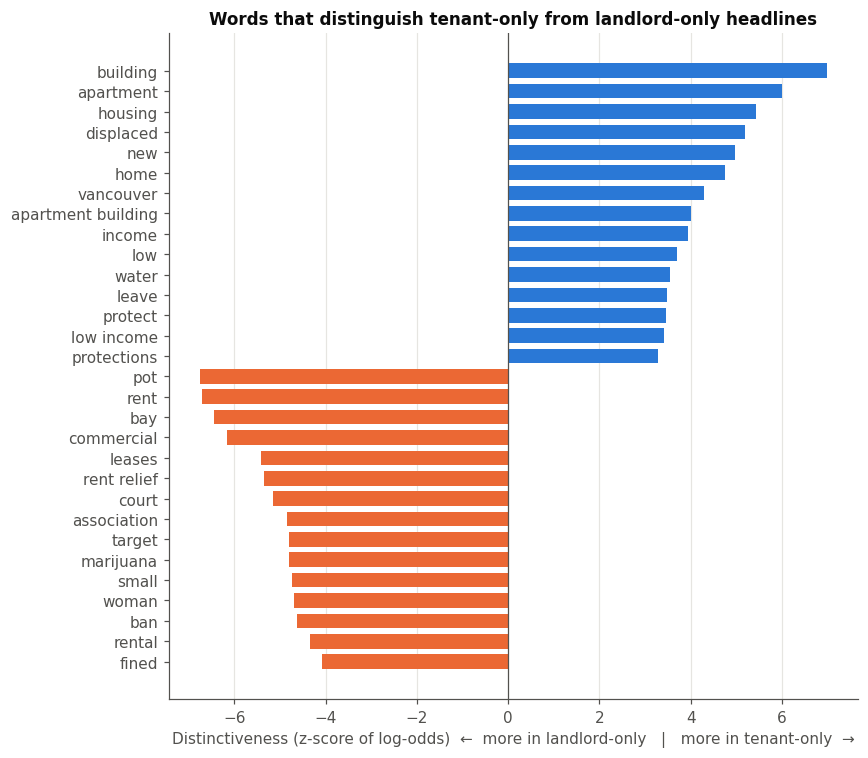

In [13]:
GROUP_WORD_RE = re.compile(r"\b(?:tenants?|tenancy|tenancies|renters?|landlords?|renting)\b", re.I)


def log_odds_dirichlet(texts_a, texts_b, min_docs=LEXICAL_MIN_DOCS, prior_strength=LEXICAL_PRIOR):
    """Monroe et al. (2008) log-odds with an informative Dirichlet prior; z-scores account for sparse counts."""
    cv = CountVectorizer(ngram_range=(1, 2), min_df=min_docs, stop_words="english", token_pattern=r"(?u)\b[a-zA-Z]{3,}\b", binary=True)
    X = cv.fit_transform(list(texts_a) + list(texts_b))
    na = len(texts_a)
    ca, cb = np.asarray(X[:na].sum(axis=0)).ravel().astype(float), np.asarray(X[na:].sum(axis=0)).ravel().astype(float)
    prior = prior_strength * (ca + cb) / (ca + cb).sum()
    a0 = prior.sum()
    la = np.log((ca + prior) / (ca.sum() + a0 - ca - prior))
    lb = np.log((cb + prior) / (cb.sum() + a0 - cb - prior))
    z = (la - lb) / np.sqrt(1 / (ca + prior) + 1 / (cb + prior))
    return pd.DataFrame({"term": cv.get_feature_names_out(), "z": z, "n_tenant_headlines": ca.astype(int), "n_landlord_headlines": cb.astype(int)})


single = prepared[prepared["is_rep_near"] & prepared["mention_group"].isin(["tenant", "landlord"])]
t_texts = single.loc[single["mention_group"] == "tenant", "title"].map(lambda t: GROUP_WORD_RE.sub(" ", t))
l_texts = single.loc[single["mention_group"] == "landlord", "title"].map(lambda t: GROUP_WORD_RE.sub(" ", t))
lo = log_odds_dirichlet(t_texts, l_texts).sort_values("z", ascending=False)
print(f"Vocabulary comparison on {len(t_texts):,} tenant-only vs {len(l_texts):,} landlord-only distinct headlines (group words removed)")
top_t, top_l = lo.head(TOP_TERMS), lo.tail(TOP_TERMS).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 7))
plot = pd.concat([top_l.iloc[::-1], top_t.iloc[::-1]])
ax.barh(plot["term"], plot["z"], color=[COLORS["tenant"] if z > 0 else COLORS["landlord"] for z in plot["z"]], height=0.72)
ax.axvline(0, color=MUTED, lw=0.8)
ax.set_xlabel("Distinctiveness (z-score of log-odds)  ←  more in landlord-only   |   more in tenant-only  →")
ax.set_title("Words that distinguish tenant-only from landlord-only headlines")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

In [14]:
GENERIC_VERBS = {"be", "have", "do", "get", "go", "make", "take", "come", "say", "look", "need", "want", "see", "give", "keep", "let", "put", "set", "use", "find", "know", "show", "become", "try"}
gv = distinct.assign(gv=distinct["gov_verbs"].fillna("").str.split("|")).explode("gv")
gv = gv[gv["gv"].notna() & (gv["gv"] != "")]
gv[["verb", "role"]] = gv["gv"].str.split(":", expand=True)
gv = gv[~gv["verb"].isin(GENERIC_VERBS)].drop_duplicates(["id", "group", "verb", "role"])
n_obs = distinct.groupby("group").size()
verb_tab = gv.groupby(["role", "verb", "group"]).size().unstack("group", fill_value=0)
for c in ["tenant", "landlord"]:
    verb_tab[f"{c}_per_1000"] = (1000 * verb_tab[c] / n_obs[c]).round(1)
print("Governing verbs when the group is the grammatical SUBJECT (per 1,000 observations of that group):")
display(verb_tab.loc["subj"].assign(total=lambda d: d["tenant"] + d["landlord"]).sort_values("total", ascending=False).head(14).drop(columns="total"))
print("Governing verbs when the group is OBJECT / PASSIVE (the thing acted upon):")
obj = pd.concat([verb_tab.loc[r] for r in ["obj", "pass"] if r in verb_tab.index.get_level_values(0)]).groupby(level=0).sum()
for c in ["tenant", "landlord"]:
    obj[f"{c}_per_1000"] = (1000 * obj[c] / n_obs[c]).round(1)
display(obj.assign(total=lambda d: d["tenant"] + d["landlord"]).sort_values("total", ascending=False).head(14).drop(columns="total"))

mods = distinct.assign(m=distinct["modifiers"].fillna("").str.split("|")).explode("m")
mods = mods[mods["m"].notna() & (mods["m"] != "")].drop_duplicates(["id", "group", "m"])
mod_tab = mods.groupby(["m", "group"]).size().unstack("group", fill_value=0)
mod_tab["total"] = mod_tab.sum(axis=1)
print("Adjectives directly modifying the group word:")
display(mod_tab.sort_values("total", ascending=False).head(18).drop(columns="total"))

Governing verbs when the group is the grammatical SUBJECT (per 1,000 observations of that group):


group,landlord,tenant,tenant_per_1000,landlord_per_1000
verb,,,,
face,18,55,12.5,7.7
leave,8,35,7.9,3.4
fight,3,35,7.9,1.3
call,13,24,5.4,5.5
pay,18,14,3.2,7.7
fear,5,26,5.9,2.1
tell,11,18,4.1,4.7
move,2,27,6.1,0.9
feel,5,22,5.0,2.1


Governing verbs when the group is OBJECT / PASSIVE (the thing acted upon):


group,landlord,tenant,tenant_per_1000,landlord_per_1000
verb,,,,
evict,2,91,20.6,0.9
protect,3,59,13.4,1.3
displace,0,61,13.8,0.0
force,11,47,10.7,4.7
help,7,48,10.9,3.0
leave,11,39,8.8,4.7
offer,5,29,6.6,2.1
charge,20,14,3.2,8.5
order,16,14,3.2,6.8


Adjectives directly modifying the group word:


group,landlord,tenant
m,,
new,13,77
former,10,34
commercial,32,8
more,6,25
bad,17,10
calgary,14,13
canadian,3,20
displace,0,21
vulnerable,0,19


In [15]:
topic_cols = [c for c in annotations.columns if c.startswith("topic_") and c != "topic_any"]
tt = distinct.groupby("group")[topic_cols].mean().T * 100
tt.index = [i.replace("topic_", "") for i in tt.index]
print("Share of distinct headlines touching each topic (%, multi-label). No topic assigned:",
      ", ".join(f"{g} {100 * (1 - distinct[distinct.group == g]['topic_any'].mean()):.1f}%" for g in ["tenant", "landlord"]))
display(tt.round(1).sort_values("tenant", ascending=False))

Share of distinct headlines touching each topic (%, multi-label). No topic assigned: tenant 31.3%, landlord 30.7%


group,landlord,tenant
conditions,11.6,19.5
eviction,12.8,18.5
dispute,26.6,15.5
regulation,14.5,12.6
investment,8.8,9.7
affordability,5.4,8.4
crime,14.5,7.6
organizing,5.6,7.2


### Does clustering add anything?

Clustering is worth keeping only if it surfaces something the hand-built topics miss. Headlines with *no* topic assigned are clustered (TF-IDF + k-means, group words removed) to see whether they hide a coherent missing theme.

In [16]:
rest = single[~single["id"].isin(distinct[distinct["topic_any"]]["id"])]
vec = TfidfVectorizer(stop_words="english", min_df=5, ngram_range=(1, 2), token_pattern=r"(?u)\b[a-zA-Z]{3,}\b")
Xr = vec.fit_transform(rest["title"].map(lambda t: GROUP_WORD_RE.sub(" ", t)))
km = KMeans(n_clusters=N_CLUSTERS, random_state=SEED, n_init=10).fit(Xr)
terms = vec.get_feature_names_out()
print(f"{len(rest):,} single-group distinct headlines have no topic assigned. Top terms of {N_CLUSTERS} clusters:")
for i in range(N_CLUSTERS):
    top = km.cluster_centers_[i].argsort()[-8:][::-1]
    print(f"  cluster {i} (n={int((km.labels_ == i).sum()):>4}): " + ", ".join(terms[top]))

1,619 single-group distinct headlines have no topic assigned. Top terms of 6 clusters:
  cluster 0 (n=  12): left, shocked, cold, sudbury, finds, alleged, manitoba, vancouver
  cluster 1 (n= 130): rent, pay, pay rent, covid, free, coronavirus, commercial, cent
  cluster 2 (n=  84): building, apartment building, apartment, new, vancouver, construction, man, langford
  cluster 3 (n= 197): new, home, ownership, home ownership, toronto, gets, gets new, tower
  cluster 4 (n=1079): city, toronto, apartment, canada, says, hamilton, rental, vancouver
  cluster 5 (n= 117): housing, social, social housing, crisis, housing crisis, public, public housing, community


In [17]:
sizes = np.bincount(km.labels_, minlength=N_CLUSTERS)
print(f"Largest cluster holds {100 * sizes.max() / sizes.sum():.0f}% of the no-topic headlines; the other {N_CLUSTERS - 1} clusters hold {100 * (1 - sizes.max() / sizes.sum()):.0f}% in total.")
print("Clustering is kept as a diagnostic only:", "no dominant missing theme" if sizes.max() / sizes.sum() > 0.5 else "several sizeable themes are missing from the topic list: consider adding them")

Largest cluster holds 67% of the no-topic headlines; the other 5 clusters hold 33% in total.
Clustering is kept as a diagnostic only: no dominant missing theme


Reading the clusters above: if they separate into named themes that the eight topic families do not cover, add a topic family; if they are mostly loose collections of place names and generic words, clustering adds little and the hand-built topics are kept. The cell below states the one number that settles it.

## 9. Human-review file

**Design.** 120 *distinct* headlines (one per story family, never two copies of one story):

* **20 pilot headlines** — read these first, compare your coding with the written definitions, and tighten the definitions if needed. They are *never* used to score the measures.
* **100 held-out validation headlines**: about **80 stratified random** (mention type tenant-only / landlord-only / both, × the engine predicting at least one framing signal or none, with soft caps so no single outlet or year dominates) and about **20 targeted difficult cases** (negation, quotation and allegation; both-group headlines with possibly crossed roles; rare signals such as derogatory language, blame, organisations, resistance; and headlines the engine left blank although they contain cue words).

**Why two components.** The random component says how accurate the engine is on typical headlines (within strata; strata weights are stored so weighted estimates can be made). The targeted component says where it breaks. The targeted sample is deliberately enriched for hard cases, so it must never be read as corpus prevalence; the two are always scored separately.

**Anchoring.** The review file contains no automatic predictions. Predictions stay in `framing_annotations.csv` and are joined back by `id` and `group` only when scoring. Sampling metadata (the `meta_*` columns, to the right of the label columns) does reveal the predicted-positive / predicted-negative stratum, so **hide those columns while coding**.

In [18]:
REVIEW_DIMS = ["act_initiate", "act_resist", "harm_experienced", "assist_received", "voice_any", "discussed_by_others", "const_org", "individual", "wrongdoing", "responsibility", "derogatory"]
REVIEW_TO_PRED = {"individual": "ind_individual", "derogatory": "derogatory_any"}          # review dimension → annotation column (others share the name)
REVIEW_TOPICS = [c.replace("topic_", "") for c in topic_cols]
PRED_ANY = ["act_initiate", "act_resist", "harm_experienced", "assist_received", "voice_any", "const_org", "wrongdoing", "responsibility", "derogatory_any"]


def review_labels_exist(path):
    if not Path(path).exists():
        return False
    df = pd.read_csv(path, dtype=str)
    label_cols = [c for c in df.columns if c.startswith("h_")]
    vals = df[label_cols].apply(lambda s: s.str.strip().str.upper().replace({"": np.nan}))
    return bool(vals.replace({"NA": np.nan}).notna().any().any())


def build_review_frame():
    reps = prepared[prepared["is_rep_near"] & prepared["mention_group"].isin(["tenant", "landlord", "both"])].copy()
    per_headline = annotations[annotations["id"].isin(reps["id"])].groupby("id")[PRED_ANY].any()
    reps["pred_any"] = reps["id"].map(per_headline.any(axis=1)).fillna(False)
    ctx = annotations.groupby("id")[["ctx_negated", "ctx_quoted", "ctx_alleged"]].any()
    reps = reps.join(ctx, on="id")
    reps["stratum"] = reps["mention_group"] + "|" + np.where(reps["pred_any"], "pred_pos", "pred_neg")
    reps["pair_conflict"] = False
    both_ids = set(reps.loc[reps["mention_group"] == "both", "id"])
    a = annotations[annotations["id"].isin(both_ids)].set_index(["id", "group"])
    crossed = []
    for rid in both_ids:
        t, l = a.loc[(rid, "tenant")], a.loc[(rid, "landlord")]
        crossed.append(rid if ((t["harm_experienced"] and l["harm_experienced"]) or (t["act_initiate"] and l["act_initiate"]) or (t["wrongdoing"] and l["wrongdoing"])
                               or (t["voice_any"] and l["voice_any"]) or (t["harm_experienced"] and l["act_initiate"])) else None)
    reps["pair_conflict"] = reps["id"].isin({c for c in crossed if c})
    return reps.sort_values("id").reset_index(drop=True)


def draw(pool, n, rng, soft_caps=True, n_total=None):
    """Random draw of n rows; optionally cap any single outlet/year at a share of the target size."""
    pool = pool.sample(frac=1, random_state=int(rng.integers(1 << 30)))
    if not soft_caps:
        return pool.head(n)
    n_total = n_total or n
    cap_src, cap_yr = max(2, int(np.ceil(MAX_PER_OUTLET_SHARE * n_total))), max(2, int(np.ceil(MAX_PER_YEAR_SHARE * n_total)))
    chosen, src_ct, yr_ct = [], {}, {}
    for r in pool.itertuples():
        if len(chosen) == n:
            break
        if src_ct.get(r.media_name, 0) < cap_src and yr_ct.get(r.year, 0) < cap_yr:
            chosen.append(r.Index); src_ct[r.media_name] = src_ct.get(r.media_name, 0) + 1; yr_ct[r.year] = yr_ct.get(r.year, 0) + 1
    if len(chosen) < n:                                    # not enough under the caps: top up from what remains
        rest = pool.drop(index=chosen)
        chosen += list(rest.head(n - len(chosen)).index)
    return pool.loc[chosen]


def build_review_sample():
    rng = np.random.default_rng(SEED)
    reps = build_review_frame()
    used, parts = set(), []

    def take(df, component, reason="", stratum_col="stratum"):
        out = df.copy()
        out["component"], out["targeted_reason"] = component, reason
        used.update(out["family_id_near"])
        parts.append(out)

    # pilot: stratified, half predicted-positive
    for g, n in PILOT_ALLOCATION.items():
        for pos, k in [(True, n - n // 2), (False, n // 2)]:
            pool = reps[(reps["mention_group"] == g) & (reps["pred_any"] == pos) & ~reps["family_id_near"].isin(used)]
            take(draw(pool, k, rng, soft_caps=False), "pilot")
    # stratified random validation
    frame_sizes = reps[~reps["family_id_near"].isin(set().union(*[set(p["family_id_near"]) for p in parts]))].groupby("stratum").size()
    for g, n in RANDOM_ALLOCATION.items():
        for pos, k in [(True, n - n // 2), (False, n // 2)]:
            pool = reps[(reps["mention_group"] == g) & (reps["pred_any"] == pos) & ~reps["family_id_near"].isin(used)]
            sel = draw(pool, k, rng, soft_caps=True, n_total=VALIDATION_RANDOM_N)
            sel = sel.assign(weight=frame_sizes.get(f"{g}|{'pred_pos' if pos else 'pred_neg'}", np.nan) / max(len(sel), 1))
            take(sel, "validation_random")
    # targeted difficult cases
    quotas = [("negation_quote_or_allegation", 5), ("both_groups_possible_crossed_roles", 5), ("rare_signal_predicted_positive", 5), ("predicted_blank_but_has_cue_words", 5)]
    cue_words = re.compile(r"\b(?:evict\w*|protect\w*|fight\w*|blame\w*|sue[ds]?|accus\w+|charged|fined|demand\w*|rally|protest\w*|association|union|advocat\w+|says?|help\w*|relief)\b", re.I)
    for reason, k in quotas:
        pool = reps[~reps["family_id_near"].isin(used)]
        if reason == "negation_quote_or_allegation":
            pool = pool[pool["ctx_negated"] | pool["ctx_quoted"] | pool["ctx_alleged"]]
        elif reason == "both_groups_possible_crossed_roles":
            pool = pool[pool["pair_conflict"]]
        elif reason == "rare_signal_predicted_positive":
            rare = annotations[annotations[["act_resist", "const_org", "responsibility", "derogatory_any", "const_policy"]].any(axis=1)]["id"]
            pool = pool[pool["id"].isin(rare)]
        else:
            pool = pool[~pool["pred_any"] & pool["title"].str.contains(cue_words)]
        take(draw(pool, k, rng, soft_caps=False), "validation_targeted", reason)
    sample = pd.concat(parts, ignore_index=True)
    return sample


sample = build_review_sample()
sample["phase"] = np.where(sample["component"] == "pilot", "pilot", "validation")
assert sample["family_id_near"].is_unique, "each review headline must come from a distinct story family"
print(sample.groupby(["phase", "component", "mention_group"]).size().unstack(fill_value=0))
print("\nOutlets in the validation sample:", sample[sample["phase"] == "validation"]["media_name"].nunique(), "| years covered:",
      sorted(sample[sample["phase"] == "validation"]["year"].unique().tolist()))

mention_group                   both  landlord  tenant
phase      component                                  
pilot      pilot                   6         6       8
validation validation_random      26        26      28
           validation_targeted    10         4       6

Outlets in the validation sample: 27 | years covered: [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]


In [19]:
def blank_label_columns(sample):
    cols = {}
    for g in ["tenant", "landlord"]:
        for d in REVIEW_DIMS:
            cols[f"h_{g}_{d}"] = np.where(sample["mention_group"].isin([g, "both"]), "", "NA")
    for t in REVIEW_TOPICS:
        cols[f"h_topic_{t}"] = ""
    return pd.DataFrame(cols, index=sample.index)


def make_review_csv(sample):
    sample = sample.sort_values(["phase", "component", "id"]).reset_index(drop=True)      # stable order, not grouped by prediction
    sample = sample.sample(frac=1, random_state=SEED).sort_values("phase", ascending=False).reset_index(drop=True)   # pilot first, shuffled within phase
    base = pd.DataFrame({
        "review_id": ["rv_" + f[4:] for f in sample["family_id_near"]], "phase": sample["phase"], "id": sample["id"], "title": sample["title"],
        "media_name": sample["media_name"], "publish_date": sample["publish_date"], "url": sample["url"], "mentions": sample["mention_group"]})
    labels = blank_label_columns(sample)
    labels["h_notes"] = ""
    meta = pd.DataFrame({"meta_component": sample["component"], "meta_stratum": sample["stratum"], "meta_targeted_reason": sample["targeted_reason"],
                         "meta_weight": sample["weight"].round(3) if "weight" in sample else np.nan})
    return pd.concat([base, labels, meta], axis=1)


review = make_review_csv(sample)
REVIEW_PATH.parent.mkdir(parents=True, exist_ok=True)
if REVIEW_PATH.exists() and review_labels_exist(REVIEW_PATH) and not REGENERATE_REVIEW:
    print(f"{REVIEW_PATH.name} already contains human labels: it is left untouched (set REGENERATE_REVIEW = True to overwrite).")
else:
    review.to_csv(REVIEW_PATH, index=False)
    print(f"Wrote {len(review)} headlines × {review.shape[1]} columns → {REVIEW_PATH}")
display(review.drop(columns=[c for c in review.columns if c.startswith("h_") and c not in ("h_notes",)]).head(6))

Wrote 120 headlines × 43 columns → ../../data/headlines/review/human_review.csv


,review_id,phase,id,title,media_name,publish_date,url,mentions,h_notes,meta_component,meta_stratum,meta_targeted_reason,meta_weight
0,rv_457cc86081,validation,457cc860816545a6af2349a889120568b45526807d101816ca1493acc5100867,B.C. tenants face extra rent hikes to fund landlords' repairs – and they're permanent,ctvnews.ca,2022-08-09,https://bc.ctvnews.ca/b-c-tenants-face-extra-rent-hikes-to-fund-landlords-repairs-and-they-re-permanent-1.6020765,both,,validation_random,both|pred_pos,,38.538
1,rv_718196efc4,validation,718196efc48873208a88de290b5b06b3cc880db63ded9a591701763767b97eb6,Why this Kensington market tenant is having to fight to stay in his apartment... again,cbc.ca,2017-06-28,http://www.cbc.ca/news/canada/toronto/kensington-residents-fights-landlord-at-board-again-1.4182743?cmp=rss,tenant,,validation_random,tenant|pred_pos,,120.143
2,rv_584ee8d432,validation,584ee8d43208c84f6cfb6dbb89fb08acacbdd536e5a9d5f8f1c51986c2ea33b9,Duff Court tenants in Lachine angry over apartment conditions,globalnews.ca,2018-03-13,https://globalnews.ca/news/4080056/duff-court-tenants-in-lachine-angry-over-apartment-conditions/,tenant,,validation_random,tenant|pred_pos,,120.143
3,rv_7a0e4cc9d2,validation,7a0e4cc9d244dc541b4ea13c70b387de33932f17d118c46eec4f992a58a01958,"Edmonton landlord, associates awarded $250 each over disclosure issue",edmontonjournal.com,2021-08-02,https://edmontonjournal.com/news/local-news/edmonton-landlord-associates-awarded-250-each-from-police-chief-over-dis...,landlord,,validation_random,landlord|pred_neg,,67.923
4,rv_3dc1d0cbf9,validation,3dc1d0cbf9784f59cd8c8dab9ed5d5bd2154aa65ea5bfecad9f8f0f5ca05b168,South River fire results in charges against landlord,nugget.ca,2022-11-11,https://www.nugget.ca/news/south-river-fire-results-in-charges-against-landlord,landlord,,validation_random,landlord|pred_pos,,49.154
5,rv_e65982155f,validation,e65982155f27d71b9808b7e752e4c772f10e1d753ec0fe6bb65946158ae6f78c,"If your landlord wants to increase your rent, here are your rights",theconversation.com,2022-09-08,https://theconversation.com/if-your-landlord-wants-to-increase-your-rent-here-are-your-rights-190126,landlord,,validation_random,landlord|pred_pos,,49.154


### Coding instructions (one page)

Open `data/headlines/review/human_review.csv` in a spreadsheet. Code **from the headline text only** — do not open the article and do not guess at the outlet's intent. Work through the 20 `pilot` rows first; if two coders disagree, fix the wording of the definition below before starting `validation` rows. Hide the `meta_*` columns.

For each headline and **each group it mentions** (columns `h_tenant_*` / `h_landlord_*`; the other group's columns are pre-filled `NA`), enter **1** if the dimension is clearly present *for that group*, **0** if not, and leave blank only if you cannot decide (explain in `h_notes`). Code the group a phrase is *about*: in "Landlord evicts tenant", landlord = initiates action, tenant = experiences harm.

| Column | Code 1 when the headline shows that group … |
|---|---|
| `act_initiate` | taking an action on others or the world (evict, raise rent, sell, build, buy, charge a fee, launch) |
| `act_resist` | responding, resisting or asserting rights (fight, sue, appeal, protest, organize, win a case, refuse) |
| `harm_experienced` | suffering harm or hardship (evicted, displaced, facing eviction, squeezed, losing money, injured, victim of crime) |
| `assist_received` | being helped or protected (protection, relief, support, compensation, housing offered) |
| `voice_any` | speaking, being quoted, making demands/claims, or having an advocate/association speak for them |
| `discussed_by_others` | being talked about or acted on by someone else (officials, courts, studies, police) with no voice of their own |
| `const_org` | tied to an organisation, association, union or advocacy group (“tenant union”, “landlord association”, “advocates say”) |
| `individual` | a personal case (a single named or described person) rather than a general group or company |
| `wrongdoing` | accused, charged, sued, fined, found guilty or described as breaking rules/laws (a lawsuit *by* the group is **not** wrongdoing) |
| `responsibility` | blamed or held responsible for a problem (“to blame”, “blamed for”) |
| `derogatory` | called by an explicitly insulting word or phrase (deadbeat, slumlord, “tenant from hell”), even if quoted |

Do **not** code: arrears or unpaid rent by itself as `wrongdoing` or `derogatory`; “protect” as loss of agency; an eviction mention as `harm_experienced` for a group that is the *evictor*; a negated claim (“not to blame”, “charges dropped”) as present. The eight `h_topic_*` columns (eviction, affordability, conditions, dispute, regulation, organizing, investment, crime) are headline-level: 1 if the headline is substantially about it. Allegation or quotation does not change the code — note it in `h_notes` if it made the call hard.

## 10. Import completed labels and assess the measures

This code runs on whatever labels exist. **If the review file has not been filled in, nothing is assessed and nothing is invented**: the workflow carries on with the automatic measures, which are then *provisional*. Point `HEADLINE_REVIEW_FILE` (or `REVIEW_LABELS_PATH`) at a completed copy to assess it.

Metrics are computed per group and dimension, **separately for the random and targeted components**, on the validation phase only (pilot rows are excluded). *Precision* = of the headlines the engine flagged, the share the human also coded 1; *recall* = of the headlines the human coded 1, the share the engine flagged. Wilson 95% intervals are shown, and any estimate with fewer than `MIN_POSITIVES` positives is flagged **too few**. Rows labelled `pooled` stack tenant and landlord observations to get more positives per dimension; the status column in section 11 uses the pooled random-sample rows. Because the random sample is stratified, treat its numbers as approximate and prefer the weighted columns.

In [20]:
YES = {"1", "Y", "YES", "TRUE", "T"}
NO = {"0", "N", "NO", "FALSE", "F"}


def load_review_labels(path):
    if not Path(path).exists() or not review_labels_exist(path):
        return None
    df = pd.read_csv(path, dtype=str)
    for c in [c for c in df.columns if c.startswith("h_") and c != "h_notes"]:
        s = df[c].fillna("").str.strip().str.upper()
        df[c] = np.where(s.isin(YES), 1.0, np.where(s.isin(NO), 0.0, np.nan))
    df["meta_weight"] = pd.to_numeric(df["meta_weight"], errors="coerce")
    return df


def prf(y, p, w=None):
    w = np.ones(len(y)) if w is None else np.asarray(w, float)
    y, p = np.asarray(y, bool), np.asarray(p, bool)
    tp, fp, fn = w[y & p].sum(), w[~y & p].sum(), w[y & ~p].sum()
    return tp, fp, fn, (tp / (tp + fp) if tp + fp else np.nan), (tp / (tp + fn) if tp + fn else np.nan)


def assess_review(labels, annotations):
    """Per (component, group, dimension) precision/recall with Wilson intervals; pilot rows excluded. 'pooled' stacks both groups."""
    lab = labels[labels["phase"] == "validation"]
    ann = annotations.set_index(["id", "group"])
    recs = []
    for r in lab.itertuples():
        for g in ["tenant", "landlord"]:
            if r.mentions not in (g, "both"):
                continue
            for d in REVIEW_DIMS:
                y = getattr(r, f"h_{g}_{d}")
                if pd.isna(y):
                    continue
                recs.append({"component": r.meta_component.replace("validation_", ""), "group": g, "dimension": d, "id": r.id, "title": r.title, "y": bool(y),
                             "pred": bool(ann.at[(r.id, g), REVIEW_TO_PRED.get(d, d)]), "w": 1.0 if pd.isna(r.meta_weight) else r.meta_weight,
                             "evidence": ann.at[(r.id, g), "evidence"][:90]})
    obs_ = pd.DataFrame(recs)
    if obs_.empty:
        return pd.DataFrame(), pd.DataFrame()
    obs_ = pd.concat([obs_, obs_.assign(group="pooled")], ignore_index=True)
    rows = []
    for (comp, g, d), s in obs_.groupby(["component", "group", "dimension"]):
        tp, fp, fn, prec, rec = prf(s["y"], s["pred"])
        _, _, _, prec_w, rec_w = prf(s["y"], s["pred"], s["w"]) if comp == "random" else (0, 0, 0, np.nan, np.nan)
        p_lo, p_hi = wilson(int(tp), int(tp + fp)) if tp + fp else (np.nan, np.nan)
        r_lo, r_hi = wilson(int(tp), int(tp + fn)) if tp + fn else (np.nan, np.nan)
        rows.append({"component": comp, "group": g, "dimension": d, "n_coded": len(s), "human_pos": int(s["y"].sum()), "pred_pos": int(s["pred"].sum()), "TP": int(tp), "FP": int(fp), "FN": int(fn),
                     "precision": prec, "prec_CI": f"{p_lo:.2f}–{p_hi:.2f}" if tp + fp else "", "recall": rec, "recall_CI": f"{r_lo:.2f}–{r_hi:.2f}" if tp + fn else "",
                     "precision_weighted": prec_w, "recall_weighted": rec_w, "reliable": bool(s["y"].sum() >= MIN_POSITIVES and s["pred"].sum() >= MIN_POSITIVES)})
    errors = obs_[obs_["y"] != obs_["pred"]].assign(error=lambda d: np.where(d["pred"], "false positive", "false negative"))
    return pd.DataFrame(rows), errors[["component", "group", "dimension", "error", "title", "evidence"]]


labels = load_review_labels(REVIEW_LABELS_PATH)
if labels is None:
    validation_summary, validation_errors = pd.DataFrame(), pd.DataFrame()
    print(f"No completed labels found in {REVIEW_LABELS_PATH.name}: validation is NOT assessed and all automatic measures remain provisional.")
else:
    validation_summary, validation_errors = assess_review(labels, annotations)
    n_val = int((labels["phase"] == "validation").sum()); n_coded = int(labels[labels["phase"] == "validation"][[c for c in labels.columns if c.startswith("h_") and c != "h_notes"]].notna().any(axis=1).sum())
    print(f"Labels found: {n_coded} of {n_val} validation headlines have at least one code.")
    display(validation_summary.round(2))
    unreliable = validation_summary[~validation_summary["reliable"]]
    print(f"\n{len(unreliable)} of {len(validation_summary)} dimension×group×component estimates rest on fewer than {MIN_POSITIVES} positives and are marked reliable=False; do not read them as accuracy.")
    if len(validation_errors):
        print("\nMost common error patterns (engine cue behind false positives):")
        fp_ev = validation_errors[(validation_errors["error"] == "false positive") & (validation_errors["group"] != "pooled")]["evidence"].str.split(r"\[|:").str[1].value_counts().head(8)
        display(fp_ev.rename("false positives").to_frame())
        print("Examples of errors:")
        display(validation_errors[validation_errors["group"] != "pooled"].groupby(["dimension", "error"]).head(2).sort_values(["dimension", "error"]).head(20))

No completed labels found in human_review.csv: validation is NOT assessed and all automatic measures remain provisional.


## 11. What the automatic measures say so far, and what still needs review

The summary is generated from the results above. Unadjusted rates are shown only as a first look; notebook 3 does the comparisons properly (distinct stories, source/year adjustment, paired comparisons, robustness).

In [21]:
def status_for(dim):
    if validation_summary.empty:
        return "needs review (no labels supplied)"
    d = dim if dim != "ind_individual" else "individual"
    d = "derogatory" if dim == "derogatory" else d
    sub = validation_summary[(validation_summary["dimension"] == d) & (validation_summary["component"] == "random") & (validation_summary["group"] == "pooled")]
    if sub.empty or not sub["reliable"].any():
        return "needs review (too few labelled positives)"
    low = sub[sub["reliable"] & ((sub["precision"] < LOW_PRECISION) | (sub["recall"] < LOW_RECALL))]
    return "unreliable → expand review" if len(low) else "checked on random sample"


rows = []
for dim in MAIN_DIMS:
    t, l = rt[(rt.dimension == dim) & (rt.group == "tenant")].iloc[0], rt[(rt.dimension == dim) & (rt.group == "landlord")].iloc[0]
    rows.append({"measure": LABELS[dim], "tenant %": round(100 * t.rate, 1), "landlord %": round(100 * l.rate, 1), "tenant k": int(t.k), "landlord k": int(l.k),
                 "gap (pp)": round(100 * (t.rate - l.rate), 1), "validation status": status_for(dim)})
summary = pd.DataFrame(rows).set_index("measure")
display(summary)

thin = summary[(summary[["tenant k", "landlord k"]].min(axis=1) < MIN_POSITIVES)].index.tolist()
lines = [f"- **{len(annotations):,} headline×group observations** were produced from {annotations['id'].nunique():,} headlines; the distinct-story view has {len(distinct):,}.",
         f"- **Validation:** {'no human labels supplied, so none of the measures is validated and every finding in notebook 3 is provisional' if validation_summary.empty else 'labels were supplied; see the assessment table above for precision, recall and which estimates are too small to read'}.",
         f"- **Rare signals (fewer than {MIN_POSITIVES} flagged headlines for at least one group):** {', '.join(thin) if thin else 'none'}. Rates for these are too thin to publish without more review.",
         f"- **Measures most dependent on definition choices** (review these first): discussed by others, blamed/held responsible, derogatory language, and the split between initiating and resisting action.",
         "- **If a central measure proves unreliable** (precision below "
         f"{LOW_PRECISION:.0%} or recall below {LOW_RECALL:.0%} with enough positives), expand the review for that measure only, rather than re-labelling everything."]
display(Markdown("\n".join(lines)))

,tenant %,landlord %,tenant k,landlord k,gap (pp),validation status
measure,,,,,,
Initiates action,3.1,10.0,136,236,-7.0,needs review (no labels supplied)
Responds / resists / asserts rights,3.8,3.1,169,72,0.8,needs review (no labels supplied)
Experiences harm,19.8,6.5,873,152,13.3,needs review (no labels supplied)
Receives assistance,7.7,1.6,339,37,6.1,needs review (no labels supplied)
"Has voice (speaks, demands, or spoken for)",10.5,11.1,465,261,-0.6,needs review (no labels supplied)
Discussed by others,19.4,19.1,855,448,0.3,needs review (no labels supplied)
Organisation / advocates attached,3.3,1.7,144,39,1.6,needs review (no labels supplied)
Individual personal case,23.4,51.6,1034,1213,-28.2,needs review (no labels supplied)
Alleged wrongdoing / sanction,2.6,10.0,115,236,-7.4,needs review (no labels supplied)


- **8,660 headline×group observations** were produced from 7,587 headlines; the distinct-story view has 6,760.
- **Validation:** no human labels supplied, so none of the measures is validated and every finding in notebook 3 is provisional.
- **Rare signals (fewer than 10 flagged headlines for at least one group):** Blamed / held responsible. Rates for these are too thin to publish without more review.
- **Measures most dependent on definition choices** (review these first): discussed by others, blamed/held responsible, derogatory language, and the split between initiating and resisting action.
- **If a central measure proves unreliable** (precision below 70% or recall below 60% with enough positives), expand the review for that measure only, rather than re-labelling everything.